<a href="https://colab.research.google.com/github/Adamssbb/Deep-Learning-Based-NIDS-with-Built-in-Explanations/blob/main/SHAP_Explainability_Analysis_for_CICIDS2017.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [3]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
RAW_DIR = os.path.join(DATA_DIR, "raw")
RAW_DIR = os.path.join(DATA_DIR, "processed")
RAW_DIR = os.path.join(DATA_DIR, "explanations")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
NOTEBOOKS_DIR = os.path.join(PROJECT_DIR, "notebooks")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")
LOGS_DIR = os.path.join(PROJECT_DIR, "logs")
METRICS_DIR = os.path.join(PROJECT_DIR, "metrics")
# Check project folder
if os.path.isdir(PROJECT_DIR):
    print("Project directory found!")
else:
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_DIR}"
    )

print("\nProject path:", PROJECT_DIR)

Project directory found!

Project path: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai


In [5]:
import os

# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai"

# Correct raw data directory
RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")

# ZIP file path
ZIP_PATH = os.path.join(RAW_DIR, "MachineLearningCSV.zip")

# Verify ZIP file
print("Checking ZIP file...")
print("Expected path:", ZIP_PATH)

if os.path.isfile(ZIP_PATH):
    print("\nZIP file found successfully!")
    print("File:", ZIP_PATH)
    print("Size:", round(os.path.getsize(ZIP_PATH) / (1024**2), 2), "MB")
else:
    print("\nZIP file NOT found!")
    print("Checking contents of raw directory:")

    if os.path.isdir(RAW_DIR):
        print(os.listdir(RAW_DIR))
    else:
        print("Raw directory does not exist:", RAW_DIR)

Checking ZIP file...
Expected path: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/raw/MachineLearningCSV.zip

ZIP file found successfully!
File: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/raw/MachineLearningCSV.zip
Size: 224.21 MB


In [6]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    csv_files = [
        name for name in zip_ref.namelist()
        if name.lower().endswith(".csv")
    ]

    print("Total CSV files:", len(csv_files))

    for i, file in enumerate(csv_files, 1):
        print(f"{i}. {file}")

Total CSV files: 8
1. MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
2. MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
3. MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
4. MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
5. MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
6. MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
7. MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
8. MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [7]:
import os
import zipfile

EXTRACT_DIR = "/content/cicids2017_raw"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Extraction directory:", EXTRACT_DIR)

Dataset extracted successfully!
Extraction directory: /content/cicids2017_raw


In [8]:
import os

all_csv_files = []

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.lower().endswith(".csv"):
            all_csv_files.append(
                os.path.join(root, file)
            )

all_csv_files.sort()

print("Total extracted CSV files:", len(all_csv_files))

for i, file in enumerate(all_csv_files, 1):
    print(f"{i}. {os.path.basename(file)}")

Total extracted CSV files: 8
1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [9]:
all_csv_files = []

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.lower().endswith(".csv"):
            all_csv_files.append(
                os.path.join(root, file)
            )

all_csv_files.sort()

print("Total extracted CSV files:", len(all_csv_files))

for i, file in enumerate(all_csv_files, 1):
    print(f"{i}. {os.path.basename(file)}")

Total extracted CSV files: 8
1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [10]:
import os
import pandas as pd

file_info = []

for file in all_csv_files:

    df_header = pd.read_csv(
        file,
        nrows=0,
        encoding="utf-8-sig"
    )

    file_info.append({
        "File": os.path.basename(file),
        "Columns": len(df_header.columns),
        "Size (MB)": round(
            os.path.getsize(file) / (1024**2), 2
        )
    })

file_info_df = pd.DataFrame(file_info)

display(file_info_df)

# Verify column consistency after removing whitespace
column_sets = []

for file in all_csv_files:
    cols = pd.read_csv(
        file,
        nrows=0,
        encoding="utf-8-sig"
    ).columns.str.strip().tolist()

    column_sets.append(cols)

consistent = all(
    cols == column_sets[0]
    for cols in column_sets
)

print("\nColumn consistency:", consistent)

,File,Columns,Size (MB)
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,79,73.55
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,79,73.34
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,79,55.62
3,Monday-WorkingHours.pcap_ISCX.csv,79,168.73
4,Thursday-WorkingHours-Afternoon-Infilteration....,79,79.25
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,79,49.61
6,Tuesday-WorkingHours.pcap_ISCX.csv,79,128.82
7,Wednesday-workingHours.pcap_ISCX.csv,79,214.74



Column consistency: True


In [11]:
import os
import pandas as pd
import numpy as np

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Processed data directory:", PROCESSED_DIR)
print("Number of raw CSV files:", len(all_csv_files))

Processed data directory: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed
Number of raw CSV files: 8


In [12]:
def clean_cicids2017(df):

    # 1. Clean column names
    df.columns = df.columns.str.strip()

    # 2. Remove duplicate rows
    df = df.drop_duplicates().copy()

    # 3. Check label column
    if "Label" not in df.columns:
        raise ValueError("Label column not found!")

    # 4. Clean attack labels
    df["Label"] = (
        df["Label"]
        .astype("string")
        .str.strip()
    )

    # 5. Convert feature columns to numeric
    feature_cols = [
        col for col in df.columns
        if col != "Label"
    ]

    for col in feature_cols:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    # 6. Replace infinity
    df = df.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # 7. Remove rows with missing values
    df = df.dropna(
        subset=feature_cols + ["Label"]
    )

    # 8. Remove blank labels
    df = df[
        df["Label"].str.len().gt(0).fillna(False)
    ]

    return df.reset_index(drop=True)

print("Cleaning function created successfully!")

Cleaning function created successfully!


In [14]:
import gc

cleaned_files = []
cleaning_report = []

for file in all_csv_files:

    filename = os.path.basename(file)

    print("\nProcessing:", filename)

    df = pd.read_csv(
        file,
        low_memory=False,
        encoding="utf-8-sig"
    )

    original_rows = len(df)

    df_clean = clean_cicids2017(df)

    cleaned_rows = len(df_clean)

    output_path = os.path.join(
        PROCESSED_DIR,
        filename
    )

    df_clean.to_csv(
        output_path,
        index=False
    )

    cleaned_files.append(output_path)

    cleaning_report.append({
        "File": filename,
        "Original Rows": original_rows,
        "Cleaned Rows": cleaned_rows,
        "Removed Rows": original_rows - cleaned_rows
    })

    print("Original rows:", original_rows)
    print("Cleaned rows:", cleaned_rows)
    print("Saved:", output_path)

    del df, df_clean
    gc.collect()

print("\nAll files processed successfully!")


Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Original rows: 225745
Cleaned rows: 223082
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Original rows: 286467
Cleaned rows: 213777
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv

Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Original rows: 191033
Cleaned rows: 184044
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Friday-WorkingHours-Morning.pcap_ISCX.csv

Processing: Monday-WorkingHours.pcap_ISCX.csv
Original rows: 529918
Cleaned rows: 502650
Saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/processed/Monday-WorkingHours.pcap_ISCX.csv

Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Original ro

In [15]:
cleaning_report_df = pd.DataFrame(
    cleaning_report
)

display(cleaning_report_df)

print("\nTotal original rows:",
      cleaning_report_df["Original Rows"].sum())

print("Total cleaned rows:",
      cleaning_report_df["Cleaned Rows"].sum())

print("Total removed rows:",
      cleaning_report_df["Removed Rows"].sum())

,File,Original Rows,Cleaned Rows,Removed Rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,223082,2663
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,213777,72690
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,184044,6989
3,Monday-WorkingHours.pcap_ISCX.csv,529918,502650,27268
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,252790,35812
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,164179,6187
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,421626,24283
7,Wednesday-workingHours.pcap_ISCX.csv,692703,610492,82211



Total original rows: 2830743
Total cleaned rows: 2572640
Total removed rows: 258103


In [16]:
for file in cleaned_files:

    filename = os.path.basename(file)

    df_labels = pd.read_csv(
        file,
        usecols=["Label"]
    )

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    print(df_labels["Label"].value_counts())

    del df_labels
    gc.collect()


Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Label
BENIGN      123083
PortScan     90694
Name: count, dtype: int64

Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    182096
Bot         1948
Name: count, dtype: int64

Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    502650
Name: count, dtype: int64

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          252754
Infiltration        36
Name: count, dtype: int64

Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        162036
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         412476
FTP-Patator      5931
SSH-Patator      3219
Name: count, dtype: int64

Wednesday-workingHours.pcap_ISCX.csv
Label
BENIGN        

In [17]:
import os
import pandas as pd
import gc

ENCODED_DIR = os.path.join(PROJECT_DIR, "data", "encoded")
os.makedirs(ENCODED_DIR, exist_ok=True)

encoded_files = []

for file in cleaned_files:

    filename = os.path.basename(file)
    print("Encoding:", filename)

    df = pd.read_csv(file, low_memory=False)

    df["Label"] = df["Label"].astype(str).str.strip()

    df["Binary_Label"] = (
        df["Label"] != "BENIGN"
    ).astype("int8")

    output_path = os.path.join(ENCODED_DIR, filename)
    df.to_csv(output_path, index=False)

    encoded_files.append(output_path)

    print(df["Binary_Label"].value_counts().sort_index())
    print()

    del df
    gc.collect()

print("Binary encoding completed!")

Encoding: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Binary_Label
0     95068
1    128014
Name: count, dtype: int64

Encoding: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Binary_Label
0    123083
1     90694
Name: count, dtype: int64

Encoding: Friday-WorkingHours-Morning.pcap_ISCX.csv
Binary_Label
0    182096
1      1948
Name: count, dtype: int64

Encoding: Monday-WorkingHours.pcap_ISCX.csv
Binary_Label
0    502650
Name: count, dtype: int64

Encoding: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Binary_Label
0    252754
1        36
Name: count, dtype: int64

Encoding: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Binary_Label
0    162036
1      2143
Name: count, dtype: int64

Encoding: Tuesday-WorkingHours.pcap_ISCX.csv
Binary_Label
0    412476
1      9150
Name: count, dtype: int64

Encoding: Wednesday-workingHours.pcap_ISCX.csv
Binary_Label
0    416736
1    193756
Name: count, dtype: int64

Binary encoding completed!


In [18]:
# Collect unique labels without combining datasets

unique_labels = set()

for file in encoded_files:
    labels = pd.read_csv(
        file,
        usecols=["Label"]
    )["Label"].dropna().unique()

    unique_labels.update(labels)

# Ensure BENIGN is class 0
attack_labels = sorted(
    label for label in unique_labels
    if label != "BENIGN"
)

label_mapping = {
    "BENIGN": 0,
    **{
        label: i
        for i, label in enumerate(attack_labels, start=1)
    }
}

print("Multiclass label mapping:")

for label, code in label_mapping.items():
    print(f"{code}: {label}")

Multiclass label mapping:
0: BENIGN
1: Bot
2: DDoS
3: DoS GoldenEye
4: DoS Hulk
5: DoS Slowhttptest
6: DoS slowloris
7: FTP-Patator
8: Heartbleed
9: Infiltration
10: PortScan
11: SSH-Patator
12: Web Attack � Brute Force
13: Web Attack � Sql Injection
14: Web Attack � XSS


In [19]:
import json

for file in encoded_files:

    print("Updating:", os.path.basename(file))

    df = pd.read_csv(file, low_memory=False)

    df["Multi_Label"] = (
        df["Label"]
        .map(label_mapping)
        .astype("int16")
    )

    df.to_csv(file, index=False)

    del df
    gc.collect()

mapping_path = os.path.join(
    ENCODED_DIR,
    "label_mapping.json"
)

with open(mapping_path, "w") as f:
    json.dump(label_mapping, f, indent=4)

print("\nMulticlass encoding completed!")
print("Mapping saved:", mapping_path)

Updating: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Updating: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Updating: Friday-WorkingHours-Morning.pcap_ISCX.csv
Updating: Monday-WorkingHours.pcap_ISCX.csv
Updating: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Updating: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Updating: Tuesday-WorkingHours.pcap_ISCX.csv
Updating: Wednesday-workingHours.pcap_ISCX.csv

Multiclass encoding completed!
Mapping saved: /content/drive/MyDrive/Colab Notebooks/deep_learning_nids_xai/data/encoded/label_mapping.json


In [20]:
split_files = {
    "train": [],
    "validation": [],
    "test": []
}

for file in encoded_files:

    name = os.path.basename(file).lower()

    if name.startswith(("monday", "tuesday", "wednesday")):
        split_files["train"].append(file)

    elif name.startswith("thursday"):
        split_files["validation"].append(file)

    elif name.startswith("friday"):
        split_files["test"].append(file)

    else:
        raise ValueError(f"Unknown capture day: {name}")

for split_name, files in split_files.items():
    print(f"\n{split_name.upper()}:")
    for file in files:
        print(" -", os.path.basename(file))


TRAIN:
 - Monday-WorkingHours.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv

VALIDATION:
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

TEST:
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv


In [21]:
split_summary = []

for split_name, files in split_files.items():

    total_rows = 0
    benign_rows = 0
    attack_rows = 0

    for file in files:

        labels = pd.read_csv(
            file,
            usecols=["Binary_Label"]
        )["Binary_Label"]

        total_rows += len(labels)
        benign_rows += int((labels == 0).sum())
        attack_rows += int((labels == 1).sum())

    split_summary.append({
        "Split": split_name,
        "Total Rows": total_rows,
        "Benign": benign_rows,
        "Attack": attack_rows
    })

split_df = pd.DataFrame(split_summary)

split_df["Percentage"] = (
    split_df["Total Rows"]
    / split_df["Total Rows"].sum()
    * 100
).round(2)

display(split_df)

,Split,Total Rows,Benign,Attack,Percentage
0,train,1534768,1331862,202906,59.66
1,validation,416969,414790,2179,16.21
2,test,620903,400247,220656,24.13


In [22]:
import pandas as pd
import os

train_file = split_files["train"][0]

df_sample = pd.read_csv(
    train_file,
    nrows=1000,
    low_memory=False
)

excluded_columns = [
    "Label",
    "Binary_Label",
    "Multi_Label"
]

feature_cols = [
    col for col in df_sample.columns
    if col not in excluded_columns
]

print("Total feature columns:", len(feature_cols))
print("Features:")

for i, col in enumerate(feature_cols, 1):
    print(f"{i}. {col}")

Total feature columns: 78
Features:
1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Min Packet Length
40. Max Packet Length
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag Count
45. SYN Flag Count
46. RST Flag Count
47. PSH Flag Co

In [23]:
leakage_candidates = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Src IP",
    "Dst IP"
]

found_leakage_cols = [
    col for col in feature_cols
    if col.lower() in {
        name.lower() for name in leakage_candidates
    }
]

print("Potential leakage columns:", found_leakage_cols)

feature_cols = [
    col for col in feature_cols
    if col not in found_leakage_cols
]

print("Remaining feature count:", len(feature_cols))

Potential leakage columns: []
Remaining feature count: 78


In [24]:
import pandas as pd
import numpy as np

def collect_feature_hashes(files, feature_cols):

    hashes = set()

    for file in files:

        print("Checking:", os.path.basename(file))

        for chunk in pd.read_csv(
            file,
            usecols=feature_cols,
            chunksize=100000
        ):

            chunk = chunk[feature_cols]

            row_hashes = pd.util.hash_pandas_object(
                chunk,
                index=False
            ).to_numpy(dtype=np.uint64)

            hashes.update(row_hashes.tolist())

    return hashes


train_hashes = collect_feature_hashes(
    split_files["train"], feature_cols
)

validation_hashes = collect_feature_hashes(
    split_files["validation"], feature_cols
)

test_hashes = collect_feature_hashes(
    split_files["test"], feature_cols
)

print("\nTrain/Validation duplicate candidates:",
      len(train_hashes & validation_hashes))

print("Train/Test duplicate candidates:",
      len(train_hashes & test_hashes))

print("Validation/Test duplicate candidates:",
      len(validation_hashes & test_hashes))

Checking: Monday-WorkingHours.pcap_ISCX.csv
Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Checking: Wednesday-workingHours.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv

Train/Validation duplicate candidates: 14513
Train/Test duplicate candidates: 15236
Validation/Test duplicate candidates: 10966


In [25]:
for file in split_files["validation"]:

    df = pd.read_csv(
        file,
        usecols=["Label"]
    )

    print(os.path.basename(file))
    print(df["Label"].unique())

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
['BENIGN' 'Infiltration']
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
['BENIGN' 'Web Attack � Brute Force' 'Web Attack � XSS'
 'Web Attack � Sql Injection']


In [26]:
import pandas as pd
import os

web_file = next(
    f for f in all_csv_files
    if "WebAttacks" in os.path.basename(f)
)

df_web = pd.read_csv(
    web_file,
    usecols=lambda c: c.strip() == "Label",
    encoding="cp1252",
    low_memory=False
)

df_web.columns = df_web.columns.str.strip()

print(df_web["Label"].value_counts())
print("\nUnique labels:")
print(df_web["Label"].unique())

Label
BENIGN                          168186
Web Attack ï¿½ Brute Force        1507
Web Attack ï¿½ XSS                 652
Web Attack ï¿½ Sql Injection        21
Name: count, dtype: int64

Unique labels:
['BENIGN' 'Web Attack ï¿½ Brute Force' 'Web Attack ï¿½ XSS'
 'Web Attack ï¿½ Sql Injection']


In [27]:
import os

SPLIT_DIR = os.path.join(
    PROJECT_DIR, "data", "day_split"
)

os.makedirs(SPLIT_DIR, exist_ok=True)

for split in ["train", "validation", "test"]:
    os.makedirs(
        os.path.join(SPLIT_DIR, split),
        exist_ok=True
    )

print("Day-separated directories created.")

Day-separated directories created.


In [28]:
import pandas as pd
import numpy as np
import gc

def filter_partition(files, output_dir, excluded_hashes=None):

    if excluded_hashes is None:
        excluded_hashes = set()

    kept_hashes = set()
    report = []

    for file in files:

        filename = os.path.basename(file)
        output_path = os.path.join(output_dir, filename)

        total = 0
        removed = 0
        first_chunk = True

        for chunk in pd.read_csv(
            file,
            chunksize=100000,
            low_memory=False
        ):

            row_hashes = pd.util.hash_pandas_object(
                chunk[feature_cols],
                index=False
            ).to_numpy(dtype=np.uint64)

            # Exclude records matching earlier partitions
            keep_mask = np.array(
                [int(h) not in excluded_hashes for h in row_hashes],
                dtype=bool
            )

            filtered = chunk.loc[keep_mask]

            filtered.to_csv(
                output_path,
                mode="w" if first_chunk else "a",
                header=first_chunk,
                index=False
            )

            first_chunk = False

            total += len(chunk)
            removed += int((~keep_mask).sum())

            kept_hashes.update(
                row_hashes[keep_mask].tolist()
            )

        report.append({
            "File": filename,
            "Original Rows": total,
            "Removed": removed,
            "Remaining": total - removed
        })

        gc.collect()

    return kept_hashes, report

In [29]:
# Training: Monday–Wednesday
train_kept, train_report = filter_partition(
    split_files["train"],
    os.path.join(SPLIT_DIR, "train")
)

# Validation: Thursday, excluding training matches
val_kept, val_report = filter_partition(
    split_files["validation"],
    os.path.join(SPLIT_DIR, "validation"),
    excluded_hashes=train_kept
)

# Testing: Friday, excluding training and validation matches
test_kept, test_report = filter_partition(
    split_files["test"],
    os.path.join(SPLIT_DIR, "test"),
    excluded_hashes=train_kept | val_kept
)

print("Day-separated filtering completed!")

Day-separated filtering completed!


In [30]:
report_df = pd.DataFrame(
    train_report + val_report + test_report
)

display(report_df)

print("Total original rows:",
      report_df["Original Rows"].sum())

print("Total removed rows:",
      report_df["Removed"].sum())

print("Total remaining rows:",
      report_df["Remaining"].sum())

,File,Original Rows,Removed,Remaining
0,Monday-WorkingHours.pcap_ISCX.csv,502650,0,502650
1,Tuesday-WorkingHours.pcap_ISCX.csv,421626,0,421626
2,Wednesday-workingHours.pcap_ISCX.csv,610492,0,610492
3,Thursday-WorkingHours-Afternoon-Infilteration....,252790,9253,243537
4,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,164179,8037,156142
5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,223082,4842,218240
6,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,213777,8623,205154
7,Friday-WorkingHours-Morning.pcap_ISCX.csv,184044,11100,172944


Total original rows: 2572640
Total removed rows: 41855
Total remaining rows: 2530785


In [31]:
print(
    "Train/Validation overlap:",
    len(train_kept & val_kept)
)

print(
    "Train/Test overlap:",
    len(train_kept & test_kept)
)

print(
    "Validation/Test overlap:",
    len(val_kept & test_kept)
)

Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0


In [32]:
import os
import pandas as pd

for file in os.listdir(
    os.path.join(SPLIT_DIR, "validation")
):
    if "WebAttacks" in file:

        path = os.path.join(
            SPLIT_DIR, "validation", file
        )

        df = pd.read_csv(
            path,
            usecols=["Label"]
        )

        print(df["Label"].value_counts())

Label
BENIGN                        153999
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64


In [33]:
import os
import pandas as pd
import json

# Locate the Web Attacks file
web_file = os.path.join(
    SPLIT_DIR,
    "validation",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv"
)

df_web = pd.read_csv(web_file, low_memory=False)

# Normalize known Web Attack labels
def fix_web_label(label):
    label = str(label).strip()

    if label == "BENIGN":
        return "BENIGN"
    elif "Brute Force" in label:
        return "Web Attack Brute Force"
    elif "XSS" in label:
        return "Web Attack XSS"
    elif "Sql Injection" in label:
        return "Web Attack Sql Injection"
    else:
        return label

df_web["Label"] = df_web["Label"].apply(fix_web_label)

# Keep binary labels consistent
df_web["Binary_Label"] = (
    df_web["Label"] != "BENIGN"
).astype("int8")

print("Corrected labels:")
print(df_web["Label"].value_counts())

Corrected labels:
Label
BENIGN                      153999
Web Attack Brute Force        1470
Web Attack XSS                 652
Web Attack Sql Injection        21
Name: count, dtype: int64


In [34]:
# Read existing mapping
mapping_path = os.path.join(
    ENCODED_DIR,
    "label_mapping.json"
)

with open(mapping_path, "r") as f:
    old_mapping = json.load(f)

# Repair the mapping keys, preserving class IDs
new_mapping = {}

for label, class_id in old_mapping.items():
    corrected_label = fix_web_label(label)

    if corrected_label in new_mapping:
        raise ValueError(
            f"Duplicate mapping: {corrected_label}"
        )

    new_mapping[corrected_label] = class_id

# Verify every label can be encoded
if not df_web["Label"].isin(new_mapping).all():
    raise ValueError("Unmapped labels detected!")

df_web["Multi_Label"] = (
    df_web["Label"]
    .map(new_mapping)
    .astype("int16")
)

# Save corrected validation file
df_web.to_csv(web_file, index=False)

# Save corrected mapping
with open(mapping_path, "w") as f:
    json.dump(new_mapping, f, indent=4)

print("Corrected validation file saved!")
print("Multiclass mapping updated!")

print("\nUpdated mapping:")
for label, class_id in sorted(
    new_mapping.items(),
    key=lambda x: x[1]
):
    print(class_id, label)

Corrected validation file saved!
Multiclass mapping updated!

Updated mapping:
0 BENIGN
1 Bot
2 DDoS
3 DoS GoldenEye
4 DoS Hulk
5 DoS Slowhttptest
6 DoS slowloris
7 FTP-Patator
8 Heartbleed
9 Infiltration
10 PortScan
11 SSH-Patator
12 Web Attack Brute Force
13 Web Attack Sql Injection
14 Web Attack XSS


In [35]:
df_check = pd.read_csv(
    web_file,
    usecols=["Label", "Binary_Label", "Multi_Label"]
)

print("Final label distribution:")
print(df_check["Label"].value_counts())

print("\nBinary distribution:")
print(df_check["Binary_Label"].value_counts())

print("\nMulticlass distribution:")
print(
    df_check.groupby(
        ["Multi_Label", "Label"]
    ).size()
)

print("\nCorrupted labels remaining:",
      df_check["Label"].str.contains(
          "\uFFFD", regex=False
      ).sum())

Final label distribution:
Label
BENIGN                      153999
Web Attack Brute Force        1470
Web Attack XSS                 652
Web Attack Sql Injection        21
Name: count, dtype: int64

Binary distribution:
Binary_Label
0    153999
1      2143
Name: count, dtype: int64

Multiclass distribution:
Multi_Label  Label                   
0            BENIGN                      153999
12           Web Attack Brute Force        1470
13           Web Attack Sql Injection        21
14           Web Attack XSS                 652
dtype: int64

Corrupted labels remaining: 0


In [36]:
!pip -q install xgboost scikit-learn joblib

In [37]:
import os
import time
import json
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [38]:
def load_split(split_name):

    folder = os.path.join(SPLIT_DIR, split_name)

    files = sorted([
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith(".csv")
    ])

    if not files:
        raise ValueError(f"No CSV files found in {folder}")

    frames = []

    for file in files:
        print("Loading:", os.path.basename(file))
        frames.append(pd.read_csv(file, low_memory=False))

    return pd.concat(frames, ignore_index=True)


train_df = load_split("train")
val_df = load_split("validation")
test_df = load_split("test")

print("\nTrain:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv

Train: (1534768, 81)
Validation: (399679, 81)
Test: (596338, 81)


In [39]:
excluded_columns = [
    "Label",
    "Binary_Label",
    "Multi_Label"
]

feature_cols = [
    col for col in train_df.columns
    if col not in excluded_columns
]

# Exclude known identifier columns if present
leakage_columns = {
    "flow id",
    "source ip",
    "destination ip",
    "src ip",
    "dst ip",
    "timestamp"
}

feature_cols = [
    col for col in feature_cols
    if col.lower() not in leakage_columns
]

X_train = train_df[feature_cols].astype("float32")
X_val = val_df[feature_cols].astype("float32")
X_test = test_df[feature_cols].astype("float32")

y_train = train_df["Binary_Label"].astype("int8")
y_val = val_df["Binary_Label"].astype("int8")
y_test = test_df["Binary_Label"].astype("int8")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Features:", len(feature_cols))

Training: (1534768, 78)
Validation: (399679, 78)
Testing: (596338, 78)
Features: 78


In [40]:
for name, X in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    values = X.to_numpy()

    print(
        name,
        "NaN:", np.isnan(values).sum(),
        "Infinity:", np.isinf(values).sum()
    )

Train NaN: 0 Infinity: 0
Validation NaN: 0 Infinity: 0
Test NaN: 0 Infinity: 0


In [41]:
benign_count = int((y_train == 0).sum())
attack_count = int((y_train == 1).sum())

scale_pos_weight = benign_count / attack_count

print("Benign:", benign_count)
print("Attack:", attack_count)
print("Scale positive weight:", round(scale_pos_weight, 4))

Benign: 1331862
Attack: 202906
Scale positive weight: 6.5639


In [42]:
start_time = time.time()

model = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

training_time = time.time() - start_time

print("\nTraining completed!")
print("Training time:", round(training_time, 2), "seconds")
print("Best iteration:", model.best_iteration)

[0]	validation_0-logloss:0.64729
[50]	validation_0-logloss:0.06484
[100]	validation_0-logloss:0.02541
[150]	validation_0-logloss:0.01918
[200]	validation_0-logloss:0.00971
[250]	validation_0-logloss:0.00705
[300]	validation_0-logloss:0.00564
[350]	validation_0-logloss:0.00493
[400]	validation_0-logloss:0.00481
[450]	validation_0-logloss:0.00476
[465]	validation_0-logloss:0.00478

Training completed!
Training time: 272.6 seconds
Best iteration: 435


In [43]:
def evaluate_binary(model, X, y, name):

    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results = {
        "Dataset": name,
        "Macro F1": f1_score(y, predictions, average="macro"),
        "Weighted F1": f1_score(y, predictions, average="weighted"),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "PR-AUC": average_precision_score(y, probabilities)
    }

    print(f"\n{name} Classification Report:")
    print(classification_report(y, predictions, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y, predictions))

    return results


val_results = evaluate_binary(
    model, X_val, y_val, "Validation"
)

test_results = evaluate_binary(
    model, X_test, y_test, "Test"
)

results_df = pd.DataFrame([
    val_results,
    test_results
])

display(results_df)


Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    397500
           1       0.95      0.86      0.91      2179

    accuracy                           1.00    399679
   macro avg       0.98      0.93      0.95    399679
weighted avg       1.00      1.00      1.00    399679

Confusion Matrix:
[[397411     89]
 [   303   1876]]

Test Classification Report:
              precision    recall  f1-score   support

           0       0.65      1.00      0.79    376248
           1       1.00      0.06      0.12    220090

    accuracy                           0.65    596338
   macro avg       0.82      0.53      0.45    596338
weighted avg       0.78      0.65      0.54    596338

Confusion Matrix:
[[376199     49]
 [205964  14126]]


,Dataset,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,Validation,0.952456,0.998994,0.954707,0.860945,0.993509,0.919305
1,Test,0.452823,0.539820,0.996543,0.064183,0.788191,0.807211


In [44]:
test_predictions = model.predict(X_test)

attack_results = test_df[["Label", "Binary_Label"]].copy()
attack_results["Prediction"] = test_predictions

attack_recall = (
    attack_results[attack_results["Binary_Label"] == 1]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

attack_recall["Recall"] = (
    attack_recall["Detected"] / attack_recall["Total"]
)

display(attack_recall)

,Total,Detected,Recall
Label,,,
Bot,1948,0,0.000000
DDoS,128012,13850,0.108193
PortScan,90130,276,0.003062


In [45]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

model.save_model(
    os.path.join(MODEL_DIR, "xgboost_binary.json")
)

results_df.to_csv(
    os.path.join(RESULT_DIR, "xgboost_binary_metrics.csv"),
    index=False
)

attack_recall.to_csv(
    os.path.join(RESULT_DIR, "xgboost_binary_attack_recall.csv")
)

joblib.dump(
    feature_cols,
    os.path.join(MODEL_DIR, "xgboost_feature_columns.pkl")
)

print("Model and evaluation results saved successfully!")

Model and evaluation results saved successfully!


In [46]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    f1_score
)

val_prob = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_values)
best_threshold = thresholds[best_index]

print("Best validation attack F1 threshold:", best_threshold)
print("Best validation attack F1:", f1_values[best_index])

Best validation attack F1 threshold: 0.082179375
Best validation attack F1: 0.9221111369443966


In [47]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

test_prob = model.predict_proba(X_test)[:, 1]

test_pred_tuned = (
    test_prob >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)

print("\nTest classification report:")
print(
    classification_report(
        y_test,
        test_pred_tuned,
        zero_division=0
    )
)

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_pred_tuned))

print("\nMacro-F1:",
      f1_score(y_test, test_pred_tuned, average="macro"))

print("Attack precision:",
      precision_score(y_test, test_pred_tuned, zero_division=0))

print("Attack recall:",
      recall_score(y_test, test_pred_tuned, zero_division=0))

Selected threshold: 0.082179375

Test classification report:
              precision    recall  f1-score   support

           0       0.72      1.00      0.84    376248
           1       1.00      0.35      0.52    220090

    accuracy                           0.76    596338
   macro avg       0.86      0.67      0.68    596338
weighted avg       0.83      0.76      0.72    596338


Confusion matrix:
[[376146    102]
 [143642  76448]]

Macro-F1: 0.6775019899103203
Attack precision: 0.9986675375571522
Attack recall: 0.34734881184969785


In [48]:
original_pred = (test_prob >= 0.5).astype(int)

comparison = pd.DataFrame([
    {
        "Threshold": 0.5,
        "Macro-F1": f1_score(
            y_test, original_pred, average="macro"
        ),
        "Precision": precision_score(
            y_test, original_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, original_pred, zero_division=0
        )
    },
    {
        "Threshold": float(best_threshold),
        "Macro-F1": f1_score(
            y_test, test_pred_tuned, average="macro"
        ),
        "Precision": precision_score(
            y_test, test_pred_tuned, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred_tuned, zero_division=0
        )
    }
], index=["Default", "Validation-tuned"])

display(comparison)

,Threshold,Macro-F1,Precision,Recall
Default,0.500000,0.452823,0.996543,0.064183
Validation-tuned,0.082179,0.677502,0.998668,0.347349


In [49]:
import os
import json
import pandas as pd

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

final_metrics = {
    "Model": "XGBoost",
    "Task": "Binary",
    "Split": "Day-separated",
    "Threshold": float(best_threshold),
    "Macro_F1": 0.6775019891,
    "Precision": 0.9986675376,
    "Recall": 0.3473488118,
    "ROC_AUC": 0.788191,
    "PR_AUC": 0.807211
}

pd.DataFrame([final_metrics]).to_csv(
    os.path.join(RESULT_DIR, "xgboost_binary_tuned_metrics.csv"),
    index=False
)

with open(
    os.path.join(RESULT_DIR, "xgboost_binary_threshold.json"),
    "w"
) as f:
    json.dump(
        {"threshold": float(best_threshold)},
        f,
        indent=4
    )

print("Tuned XGBoost results saved successfully!")

Tuned XGBoost results saved successfully!


In [50]:
import pandas as pd

attack_results_tuned = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_tuned["Prediction"] = test_pred_tuned

attack_recall_tuned = (
    attack_results_tuned[
        attack_results_tuned["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

attack_recall_tuned["Recall"] = (
    attack_recall_tuned["Detected"]
    / attack_recall_tuned["Total"]
)

print("Per-attack-type recall after threshold tuning:")
display(attack_recall_tuned)

attack_recall_tuned.to_csv(
    os.path.join(
        RESULT_DIR,
        "xgboost_binary_tuned_attack_recall.csv"
    )
)

Per-attack-type recall after threshold tuning:


,Total,Detected,Recall
Label,,,
Bot,1948,0,0.000000
DDoS,128012,75443,0.589343
PortScan,90130,1005,0.011151


In [51]:
from sklearn.preprocessing import StandardScaler
import joblib
import numpy as np
import os

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(
    X_train
).astype(np.float32)

# Apply same scaler to validation and test
X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test
).astype(np.float32)

# Save scaler
joblib.dump(
    scaler,
    os.path.join(
        PROJECT_DIR,
        "models",
        "standard_scaler.pkl"
    )
)

print("Scaling completed!")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("NaN in training:",
      np.isnan(X_train_scaled).sum())

print("Infinity in training:",
      np.isinf(X_train_scaled).sum())

Scaling completed!
Training: (1534768, 78)
Validation: (399679, 78)
Testing: (596338, 78)
NaN in training: 0
Infinity in training: 0


In [52]:
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_val_cnn = X_val_scaled.reshape(
    X_val_scaled.shape[0],
    X_val_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("CNN Training:", X_train_cnn.shape)
print("CNN Validation:", X_val_cnn.shape)
print("CNN Testing:", X_test_cnn.shape)

CNN Training: (1534768, 78, 1)
CNN Validation: (399679, 78, 1)
CNN Testing: (596338, 78, 1)


In [53]:
import tensorflow as tf
import numpy as np
import pandas as pd
import time
import os

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow version:", tf.__version__)

print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: []


In [54]:
cnn_model = Sequential([

    Input(shape=(78, 1)),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dropout(0.2),

    Dense(1, activation="sigmoid")

])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 78, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 78, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 39, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 39, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 39, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 19, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2432)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       311,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,473 (1.32 MB)

 Trainable params: 345,089 (1.32 MB)

 Non-trainable params: 384 (1.50 KB)

In [55]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("1D-CNN model compiled successfully!")

1D-CNN model compiled successfully!


In [56]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.asarray(y_train)
)

class_weights = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("Class weights:", class_weights)

Class weights: {0: 0.5761738077969039, 1: 3.7819680048889635}


In [57]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

cnn_path = os.path.join(
    MODEL_DIR,
    "cnn_binary_best.keras"
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=cnn_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )

]

print("Callbacks configured successfully!")

Callbacks configured successfully!


In [58]:
start_time = time.time()

cnn_history = cnn_model.fit(

    X_train_cnn,
    np.asarray(y_train),

    validation_data=(
        X_val_cnn,
        np.asarray(y_val)
    ),

    epochs=30,

    batch_size=1024,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)

cnn_training_time = time.time() - start_time

print("\nCNN training completed!")

print(
    "Training time:",
    round(cnn_training_time, 2),
    "seconds"
)

print(
    "Epochs completed:",
    len(cnn_history.history["loss"])
)

Epoch 1/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 415s 275ms/step - accuracy: 0.9780 - auc: 0.9985 - loss: 0.0444 - precision: 0.8637 - recall: 0.9894 - val_accuracy: 0.9861 - val_auc: 0.8125 - val_loss: 0.0826 - val_precision: 0.0021 - val_recall: 0.0032 - learning_rate: 0.0010
Epoch 2/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 424s 283ms/step - accuracy: 0.9861 - auc: 0.9993 - loss: 0.0263 - precision: 0.9080 - recall: 0.9958 - val_accuracy: 0.9607 - val_auc: 0.8881 - val_loss: 0.1098 - val_precision: 0.0117 - val_recall: 0.0743 - learning_rate: 0.0010
Epoch 3/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 404s 269ms/step - accuracy: 0.9904 - auc: 0.9995 - loss: 0.0195 - precision: 0.9343 - recall: 0.9973 - val_accuracy: 0.9811 - val_auc: 0.9129 - val_loss: 0.0814 - val_precision: 0.0261 - val_recall: 0.0679 - learning_rate: 0.0010
Epoch 4/30
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 500s 308ms/step - accuracy: 0.9925 - auc: 0.9997 - loss: 0.0158 - precision: 0.9479 - recall: 0.9980 - val_accuracy: 0.9789 - val_auc: 0.9461 

In [59]:
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

history_df = pd.DataFrame(cnn_history.history)

history_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_training_history.csv"
    ),
    index=False
)

print("CNN training history saved!")

CNN training history saved!


In [60]:
import os
import tensorflow as tf

cnn_path = os.path.join(
    PROJECT_DIR,
    "models",
    "cnn_binary_best.keras"
)

cnn_best = tf.keras.models.load_model(cnn_path)

print("Best CNN model loaded successfully!")
cnn_best.summary()

Best CNN model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 78, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 78, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 39, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 39, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 39, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 19, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2432)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       311,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035,653 (3.95 MB)

 Trainable params: 345,089 (1.32 MB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 690,180 (2.63 MB)

In [61]:
import numpy as np

val_prob_cnn = cnn_best.predict(
    X_val_cnn,
    batch_size=2048,
    verbose=1
).ravel()

print("Validation probabilities shape:", val_prob_cnn.shape)

print("Minimum probability:", val_prob_cnn.min())
print("Maximum probability:", val_prob_cnn.max())

196/196 ━━━━━━━━━━━━━━━━━━━━ 24s 121ms/step
Validation probabilities shape: (399679,)
Minimum probability: 0.0
Maximum probability: 0.9998449


In [62]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

val_pred_default = (
    val_prob_cnn >= 0.5
).astype(int)

print("CNN Validation Classification Report:")
print(
    classification_report(
        y_val,
        val_pred_default,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, val_pred_default))

print("Macro-F1:",
      f1_score(y_val, val_pred_default, average="macro"))

print("ROC-AUC:",
      roc_auc_score(y_val, val_prob_cnn))

print("PR-AUC:",
      average_precision_score(y_val, val_prob_cnn))

CNN Validation Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    397500
           1       0.02      0.02      0.02      2179

    accuracy                           0.99    399679
   macro avg       0.51      0.51      0.51    399679
weighted avg       0.99      0.99      0.99    399679

Confusion Matrix:
[[395467   2033]
 [  2137     42]]
Macro-F1: 0.5072507621821855
ROC-AUC: 0.9316023188757176
PR-AUC: 0.04748051241204468


In [63]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob_cnn
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)

cnn_best_threshold = float(thresholds[best_index])

print("Best CNN threshold:", cnn_best_threshold)
print("Best validation attack F1:", f1_scores[best_index])

Best CNN threshold: 0.01195597369223833
Best validation attack F1: 0.16470493389213253


In [64]:
test_prob_cnn = cnn_best.predict(
    X_test_cnn,
    batch_size=2048,
    verbose=1
).ravel()

test_pred_cnn_default = (
    test_prob_cnn >= 0.5
).astype(int)

test_pred_cnn_tuned = (
    test_prob_cnn >= cnn_best_threshold
).astype(int)

print("CNN TEST RESULTS — DEFAULT THRESHOLD")
print(
    classification_report(
        y_test,
        test_pred_cnn_default,
        zero_division=0
    )
)

print("CNN TEST RESULTS — TUNED THRESHOLD")
print(
    classification_report(
        y_test,
        test_pred_cnn_tuned,
        zero_division=0
    )
)

print("Tuned confusion matrix:")
print(confusion_matrix(y_test, test_pred_cnn_tuned))

292/292 ━━━━━━━━━━━━━━━━━━━━ 35s 119ms/step
CNN TEST RESULTS — DEFAULT THRESHOLD
              precision    recall  f1-score   support

           0       0.71      0.99      0.82    376248
           1       0.96      0.29      0.45    220090

    accuracy                           0.73    596338
   macro avg       0.83      0.64      0.64    596338
weighted avg       0.80      0.73      0.69    596338

CNN TEST RESULTS — TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.74      0.97      0.84    376248
           1       0.89      0.42      0.57    220090

    accuracy                           0.77    596338
   macro avg       0.81      0.69      0.70    596338
weighted avg       0.80      0.77      0.74    596338

Tuned confusion matrix:
[[364659  11589]
 [127706  92384]]


In [65]:
import pandas as pd

def cnn_metrics(y_true, y_pred, probabilities, threshold_name):

    return {
        "Model": "1D-CNN",
        "Threshold": threshold_name,
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted"
        ),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }

cnn_results = pd.DataFrame([
    cnn_metrics(
        y_test,
        test_pred_cnn_default,
        test_prob_cnn,
        "Default 0.5"
    ),
    cnn_metrics(
        y_test,
        test_pred_cnn_tuned,
        test_prob_cnn,
        f"Tuned {cnn_best_threshold:.6f}"
    )
])

display(cnn_results)

,Model,Threshold,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,1D-CNN,Default 0.5,0.636032,0.685454,0.958102,0.291753,0.911235,0.856985
1,1D-CNN,Tuned 0.011956,0.704898,0.740180,0.888538,0.419756,0.911235,0.856985


In [66]:
attack_results_cnn = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_cnn["Prediction"] = test_pred_cnn_tuned

cnn_attack_recall = (
    attack_results_cnn[
        attack_results_cnn["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

cnn_attack_recall["Recall"] = (
    cnn_attack_recall["Detected"]
    / cnn_attack_recall["Total"]
)

display(cnn_attack_recall)

,Total,Detected,Recall
Label,,,
Bot,1948,3,0.001540
DDoS,128012,76399,0.596811
PortScan,90130,15982,0.177322


In [67]:
import json

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

cnn_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_metrics.csv"
    ),
    index=False
)

cnn_attack_recall.to_csv(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_attack_recall.csv"
    )
)

with open(
    os.path.join(
        RESULT_DIR,
        "cnn_binary_threshold.json"
    ),
    "w"
) as f:
    json.dump(
        {"threshold": cnn_best_threshold},
        f,
        indent=4
    )

print("CNN evaluation results saved successfully!")

CNN evaluation results saved successfully!


In [68]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import os

def compare_model(name, predictions, probabilities):
    return {
        "Model": name,
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    }

comparison_df = pd.DataFrame([
    compare_model(
        "XGBoost",
        test_pred_tuned,
        test_prob
    ),
    compare_model(
        "1D-CNN",
        test_pred_cnn_tuned,
        test_prob_cnn
    )
])

display(comparison_df)

comparison_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results",
        "xgboost_vs_cnn_binary.csv"
    ),
    index=False
)

print("Comparison saved successfully!")

,Model,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBoost,0.677502,0.719943,0.998668,0.347349,0.788191,0.807211
1,1D-CNN,0.704898,0.740180,0.888538,0.419756,0.911235,0.856985


Comparison saved successfully!


In [69]:
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: []


In [70]:
X_train_lstm = X_train_cnn
X_val_lstm = X_val_cnn
X_test_lstm = X_test_cnn

print("LSTM Training:", X_train_lstm.shape)
print("LSTM Validation:", X_val_lstm.shape)
print("LSTM Testing:", X_test_lstm.shape)

assert X_train_lstm.shape[1:] == (78, 1)
assert X_val_lstm.shape[1:] == (78, 1)
assert X_test_lstm.shape[1:] == (78, 1)

LSTM Training: (1534768, 78, 1)
LSTM Validation: (399679, 78, 1)
LSTM Testing: (596338, 78, 1)


In [71]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout
)

lstm_model = Sequential([
    Input(shape=(78, 1)),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        1,
        activation="sigmoid"
    )
])

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("LSTM model compiled successfully!")

LSTM model compiled successfully!


In [73]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

lstm_path = os.path.join(
    MODEL_DIR,
    "lstm_binary_best.keras"
)

lstm_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath=lstm_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

In [77]:
import time

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_lstm,
    np.asarray(y_train),

    validation_data=(
        X_val_lstm,
        np.asarray(y_val)
    ),

    epochs=20,
    batch_size=1024,

    class_weight=class_weights,

    callbacks=lstm_callbacks,
    verbose=1
)

lstm_training_time = time.time() - start_time

print("\nLSTM training completed!")
print("Training time:", round(lstm_training_time, 2), "seconds")
print("Epochs completed:", len(lstm_history.history["loss"]))

Epoch 1/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 226s 151ms/step - accuracy: 0.9919 - auc: 0.9992 - loss: 0.0230 - precision: 0.9468 - recall: 0.9949 - val_accuracy: 0.9888 - val_auc: 0.8557 - val_loss: 0.0423 - val_precision: 0.0167 - val_recall: 0.0184 - learning_rate: 3.1250e-05
Epoch 2/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 207s 138ms/step - accuracy: 0.9920 - auc: 0.9993 - loss: 0.0223 - precision: 0.9475 - recall: 0.9950 - val_accuracy: 0.9894 - val_auc: 0.8262 - val_loss: 0.0422 - val_precision: 0.0168 - val_recall: 0.0165 - learning_rate: 3.1250e-05
Epoch 3/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 281s 151ms/step - accuracy: 0.9923 - auc: 0.9993 - loss: 0.0219 - precision: 0.9490 - recall: 0.9951 - val_accuracy: 0.9892 - val_auc: 0.8351 - val_loss: 0.0418 - val_precision: 0.0163 - val_recall: 0.0165 - learning_rate: 1.5625e-05
Epoch 4/20
1499/1499 ━━━━━━━━━━━━━━━━━━━━ 208s 139ms/step - accuracy: 0.9923 - auc: 0.9993 - loss: 0.0218 - precision: 0.9487 - recall: 0.9952 - val_accuracy: 0.9893 - val_

In [79]:
import pandas as pd

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

lstm_history_df = pd.DataFrame(lstm_history.history)

lstm_history_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_training_history.csv"
    ),
    index=False
)

print("LSTM training history saved!")

LSTM training history saved!


In [80]:
import os
import tensorflow as tf

lstm_path = os.path.join(
    PROJECT_DIR,
    "models",
    "lstm_binary_best.keras"
)

lstm_best = tf.keras.models.load_model(lstm_path)

print("Best LSTM model loaded successfully!")
lstm_best.summary()

Best LSTM model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,325 (63.77 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,884 (42.52 KB)

In [81]:
import numpy as np

val_prob_lstm = lstm_best.predict(
    X_val_lstm,
    batch_size=2048,
    verbose=1
).ravel()

print("Validation probability shape:", val_prob_lstm.shape)

print("Minimum:", val_prob_lstm.min())
print("Maximum:", val_prob_lstm.max())
print("Mean:", val_prob_lstm.mean())

196/196 ━━━━━━━━━━━━━━━━━━━━ 38s 195ms/step
Validation probability shape: (399679,)
Minimum: 7.601602e-06
Maximum: 0.99990803
Mean: 0.007686468


In [82]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    average_precision_score
)

val_pred_lstm_default = (
    val_prob_lstm >= 0.5
).astype(int)

print("LSTM VALIDATION CLASSIFICATION REPORT")

print(
    classification_report(
        y_val,
        val_pred_lstm_default,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred_lstm_default))

print("\nMacro-F1:",
      f1_score(
          y_val,
          val_pred_lstm_default,
          average="macro"
      ))

print("ROC-AUC:",
      roc_auc_score(y_val, val_prob_lstm))

print("PR-AUC:",
      average_precision_score(y_val, val_prob_lstm))

LSTM VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    397500
           1       0.02      0.02      0.02      2179

    accuracy                           0.99    399679
   macro avg       0.51      0.51      0.51    399679
weighted avg       0.99      0.99      0.99    399679


Confusion Matrix:
[[395368   2132]
 [  2141     38]]

Macro-F1: 0.5060502498766201
ROC-AUC: 0.93421906361755
PR-AUC: 0.04555158400100698


In [83]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_prob_lstm
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)

lstm_best_threshold = float(
    thresholds[best_index]
)

print("Best LSTM threshold:", lstm_best_threshold)

print("Best validation attack F1:",
      f1_scores[best_index])

Best LSTM threshold: 0.006106487009674311
Best validation attack F1: 0.1379334427487507


In [84]:
test_prob_lstm = lstm_best.predict(
    X_test_lstm,
    batch_size=2048,
    verbose=1
).ravel()

test_pred_lstm_default = (
    test_prob_lstm >= 0.5
).astype(int)

test_pred_lstm_tuned = (
    test_prob_lstm >= lstm_best_threshold
).astype(int)

print("LSTM TEST — DEFAULT THRESHOLD")

print(
    classification_report(
        y_test,
        test_pred_lstm_default,
        zero_division=0
    )
)

print("\nLSTM TEST — TUNED THRESHOLD")

print(
    classification_report(
        y_test,
        test_pred_lstm_tuned,
        zero_division=0
    )
)

print("\nTuned Confusion Matrix:")
print(confusion_matrix(y_test, test_pred_lstm_tuned))

292/292 ━━━━━━━━━━━━━━━━━━━━ 49s 167ms/step
LSTM TEST — DEFAULT THRESHOLD
              precision    recall  f1-score   support

           0       0.66      0.99      0.79    376248
           1       0.90      0.11      0.19    220090

    accuracy                           0.67    596338
   macro avg       0.78      0.55      0.49    596338
weighted avg       0.75      0.67      0.57    596338


LSTM TEST — TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.78      0.95      0.86    376248
           1       0.86      0.55      0.67    220090

    accuracy                           0.80    596338
   macro avg       0.82      0.75      0.76    596338
weighted avg       0.81      0.80      0.79    596338


Tuned Confusion Matrix:
[[356004  20244]
 [ 99350 120740]]


In [85]:
attack_results_lstm = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_lstm["Prediction"] = test_pred_lstm_tuned

lstm_attack_recall = (
    attack_results_lstm[
        attack_results_lstm["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

lstm_attack_recall["Recall"] = (
    lstm_attack_recall["Detected"]
    / lstm_attack_recall["Total"]
)

display(lstm_attack_recall)

,Total,Detected,Recall
Label,,,
Bot,1948,55,0.028234
DDoS,128012,108517,0.847710
PortScan,90130,12168,0.135005


In [86]:
import pandas as pd
import numpy as np
import os
import json

from IPython.display import display

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

# Function to evaluate LSTM binary classification
def evaluate_lstm(y_true, y_pred, probabilities, threshold_name):

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    probabilities = np.asarray(probabilities).ravel()

    return {
        "Model": "LSTM",
        "Task": "Binary",
        "Threshold": threshold_name,

        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "ROC-AUC": (
            roc_auc_score(y_true, probabilities)
            if len(np.unique(y_true)) == 2 else np.nan
        ),

        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


# Evaluate default and tuned thresholds
lstm_results = pd.DataFrame([
    evaluate_lstm(
        y_test,
        test_pred_lstm_default,
        test_prob_lstm,
        "Default 0.5"
    ),

    evaluate_lstm(
        y_test,
        test_pred_lstm_tuned,
        test_prob_lstm,
        f"Tuned {lstm_best_threshold:.8f}"
    )
])

# Display results
print("LSTM Evaluation Results:")
display(lstm_results.round(4))


LSTM Evaluation Results:


,Model,Task,Threshold,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,LSTM,Binary,Default 0.5,0.4897,0.5682,0.9008,0.1062,0.8714,0.8079
1,LSTM,Binary,Tuned 0.00610649,0.7625,0.7870,0.8564,0.5486,0.8714,0.8079


In [87]:
attack_results_lstm = test_df[
    ["Label", "Binary_Label"]
].copy()

attack_results_lstm["Prediction"] = test_pred_lstm_tuned

lstm_attack_recall = (
    attack_results_lstm[
        attack_results_lstm["Binary_Label"] == 1
    ]
    .groupby("Label")
    .agg(
        Total=("Prediction", "size"),
        Detected=("Prediction", "sum")
    )
)

lstm_attack_recall["Recall"] = (
    lstm_attack_recall["Detected"]
    / lstm_attack_recall["Total"]
)

print("LSTM per-attack-type recall:")
display(lstm_attack_recall)

LSTM per-attack-type recall:


,Total,Detected,Recall
Label,,,
Bot,1948,55,0.028234
DDoS,128012,108517,0.847710
PortScan,90130,12168,0.135005


In [88]:
import os
import json

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# Save LSTM classification metrics
lstm_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_metrics.csv"
    ),
    index=False
)

# Save LSTM per-attack-type recall
lstm_attack_recall.to_csv(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_attack_recall.csv"
    )
)

# Save optimized LSTM threshold
with open(
    os.path.join(
        RESULT_DIR,
        "lstm_binary_threshold.json"
    ),
    "w"
) as f:
    json.dump(
        {"threshold": float(lstm_best_threshold)},
        f,
        indent=4
    )

print("LSTM evaluation results saved successfully!")

print("\nSaved files:")
print(os.listdir(RESULT_DIR))

LSTM evaluation results saved successfully!

Saved files:
['metrics', 'figures', 'logs', 'xgboost_binary_metrics.csv', 'xgboost_binary_attack_recall.csv', 'xgboost_binary_tuned_metrics.csv', 'xgboost_binary_threshold.json', 'xgboost_binary_tuned_attack_recall.csv', 'cnn_binary_training_history.csv', 'cnn_binary_metrics.csv', 'cnn_binary_attack_recall.csv', 'cnn_binary_threshold.json', 'xgboost_vs_cnn_binary.csv', 'lstm_binary_training_history.csv', 'lstm_binary_metrics.csv', 'lstm_binary_attack_recall.csv', 'lstm_binary_threshold.json', 'three_models_binary_comparison.csv']


In [89]:
files_to_check = [
    "lstm_binary_metrics.csv",
    "lstm_binary_attack_recall.csv",
    "lstm_binary_threshold.json"
]

for filename in files_to_check:
    path = os.path.join(RESULT_DIR, filename)

    if os.path.isfile(path):
        print("SUCCESS:", filename)
    else:
        print("MISSING:", filename)

SUCCESS: lstm_binary_metrics.csv
SUCCESS: lstm_binary_attack_recall.csv
SUCCESS: lstm_binary_threshold.json


In [90]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

print("LSTM TEST REPORT — TUNED THRESHOLD")

print(
    classification_report(
        y_test,
        test_pred_lstm_tuned,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred_lstm_tuned))

print("\nMacro-F1:",
      f1_score(y_test, test_pred_lstm_tuned, average="macro"))

print("Attack precision:",
      precision_score(y_test, test_pred_lstm_tuned, zero_division=0))

print("Attack recall:",
      recall_score(y_test, test_pred_lstm_tuned, zero_division=0))

LSTM TEST REPORT — TUNED THRESHOLD
              precision    recall  f1-score   support

           0       0.78      0.95      0.86    376248
           1       0.86      0.55      0.67    220090

    accuracy                           0.80    596338
   macro avg       0.82      0.75      0.76    596338
weighted avg       0.81      0.80      0.79    596338


Confusion Matrix:
[[356004  20244]
 [ 99350 120740]]

Macro-F1: 0.7624854967400256
Attack precision: 0.8564092379277081
Attack recall: 0.5485937570993684


In [91]:
import pandas as pd
import os

def model_metrics(name, predictions, probabilities):
    return {
        "Model": name,
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted"
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    }

final_comparison = pd.DataFrame([
    model_metrics(
        "XGBoost",
        test_pred_tuned,
        test_prob
    ),
    model_metrics(
        "1D-CNN",
        test_pred_cnn_tuned,
        test_prob_cnn
    ),
    model_metrics(
        "LSTM",
        test_pred_lstm_tuned,
        test_prob_lstm
    )
])

display(final_comparison)

RESULT_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULT_DIR, exist_ok=True)

final_comparison.to_csv(
    os.path.join(
        RESULT_DIR,
        "three_models_binary_comparison.csv"
    ),
    index=False
)

print("Three-model comparison saved successfully!")

,Model,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBoost,0.677502,0.719943,0.998668,0.347349,0.788191,0.807211
1,1D-CNN,0.704898,0.740180,0.888538,0.419756,0.911235,0.856985
2,LSTM,0.762485,0.787023,0.856409,0.548594,0.871422,0.807915


Three-model comparison saved successfully!


In [93]:
display(lstm_results)
import pandas as pd

,Model,Task,Threshold,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,LSTM,Binary,Default 0.5,0.489744,0.568232,0.900805,0.106207,0.871422,0.807915
1,LSTM,Binary,Tuned 0.00610649,0.762485,0.787023,0.856409,0.548594,0.871422,0.807915


In [94]:
!pip -q install shap

In [95]:
import os
import time
import json
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

print("SHAP version:", shap.__version__)
print("XGBoost version:", xgb.__version__)

SHAP version: 0.54.1
XGBoost version: 3.4.1


In [96]:
xgb_path = os.path.join(
    MODEL_DIR,
    "xgboost_binary.json"
)

assert os.path.isfile(xgb_path), (
    f"XGBoost model not found: {xgb_path}"
)

xgb_model = xgb.XGBClassifier()
xgb_model.load_model(xgb_path)

print("XGBoost model loaded successfully!")
print("Number of features:", xgb_model.n_features_in_)

XGBoost model loaded successfully!
Number of features: 78


In [97]:
feature_path = os.path.join(
    MODEL_DIR,
    "xgboost_feature_columns.pkl"
)

feature_cols = joblib.load(feature_path)

print("Total features:", len(feature_cols))

for i, feature in enumerate(feature_cols, 1):
    print(f"{i}. {feature}")

Total features: 78
1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Min Packet Length
40. Max Packet Length
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag Count
45. SYN Flag Count
46. RST Flag Count
47. PSH Flag Count
48. ACK Flag 

In [98]:
sample_sizes = {
    "BENIGN": 250,
    "Bot": 150,
    "DDoS": 300,
    "PortScan": 300
}

sample_frames = []

for label, n in sample_sizes.items():

    subset = test_df[
        test_df["Label"] == label
    ]

    sample = subset.sample(
        n=min(n, len(subset)),
        random_state=42
    )

    sample_frames.append(sample)

shap_sample_df = pd.concat(
    sample_frames,
    ignore_index=True
)

X_shap = shap_sample_df[
    feature_cols
].copy()

X_shap = X_shap.astype(np.float32)

print("SHAP sample shape:", X_shap.shape)

print("\nSample distribution:")
print(shap_sample_df["Label"].value_counts())

SHAP sample shape: (1000, 78)

Sample distribution:
Label
PortScan    300
DDoS        300
BENIGN      250
Bot         150
Name: count, dtype: int64


In [99]:
assert np.isfinite(X_shap.to_numpy()).all(), (
    "SHAP sample contains NaN or infinity"
)

assert list(X_shap.columns) == list(feature_cols)

print("SHAP input validation passed!")

SHAP input validation passed!


In [100]:
start_time = time.perf_counter()

explainer_xgb = shap.TreeExplainer(
    xgb_model,
    model_output="raw"
)

shap_values_xgb = explainer_xgb(
    X_shap,
    check_additivity=True
)

shap_time_xgb = time.perf_counter() - start_time

print("SHAP calculation completed!")

print("SHAP values shape:", shap_values_xgb.values.shape)

print(
    "Total explanation time:",
    round(shap_time_xgb, 3),
    "seconds"
)

print(
    "Average explanation time:",
    round(
        shap_time_xgb / len(X_shap) * 1000,
        3
    ),
    "milliseconds per sample"
)

SHAP calculation completed!
SHAP values shape: (1000, 78)
Total explanation time: 6.109 seconds
Average explanation time: 6.109 milliseconds per sample


In [103]:
import os
import matplotlib.pyplot as plt

# Define directory for SHAP results
SHAP_DIR = "/content/SHAP_Results"

# Create directory if it does not exist
os.makedirs(SHAP_DIR, exist_ok=True)

print("SHAP directory created:", SHAP_DIR)

SHAP directory created: /content/SHAP_Results


In [104]:
# Save XGBoost Global SHAP Feature Importance
plt.savefig(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_global_bar.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP graph saved successfully!")

<Figure size 640x480 with 0 Axes>

SHAP graph saved successfully!


In [105]:
import os

file_path = os.path.join(
    SHAP_DIR,
    "xgboost_shap_global_bar.png"
)

if os.path.exists(file_path):
    print("SHAP graph successfully saved!")
    print("File location:", file_path)
else:
    print("SHAP graph not found.")

SHAP graph successfully saved!
File location: /content/SHAP_Results/xgboost_shap_global_bar.png


In [106]:
from google.colab import drive
import os

drive.mount("/content/drive")

SHAP_DIR = "/content/drive/MyDrive/NIDS_Project/SHAP_Results"

os.makedirs(SHAP_DIR, exist_ok=True)

print("SHAP results directory:", SHAP_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SHAP results directory: /content/drive/MyDrive/NIDS_Project/SHAP_Results


/tmp/ipykernel_760/2339092901.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


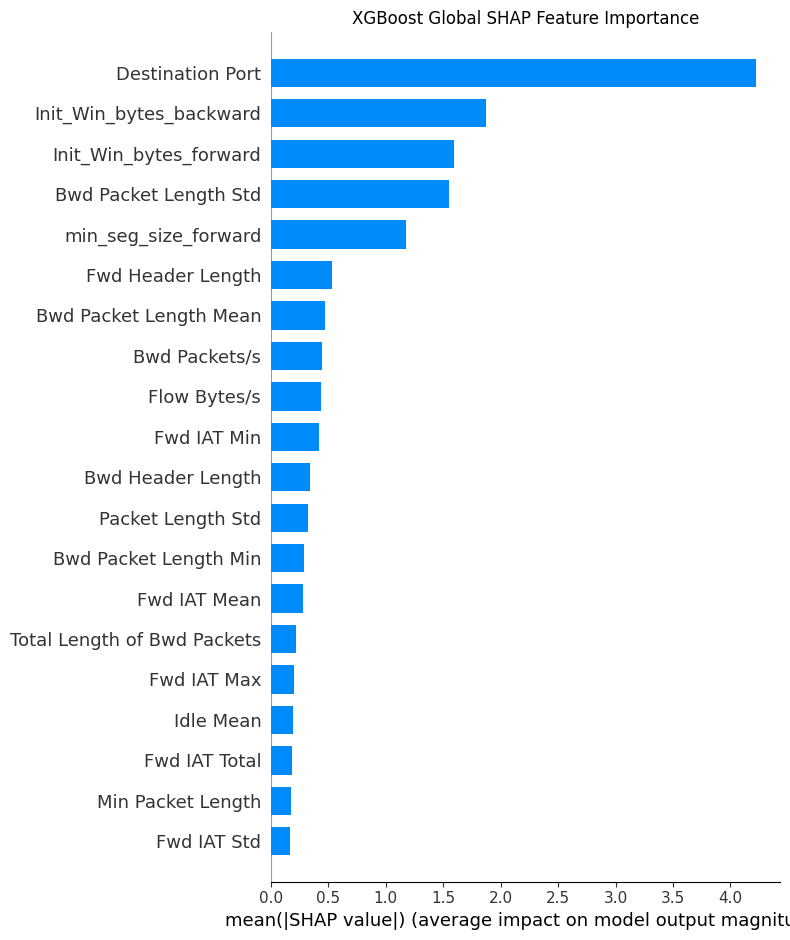

In [107]:
plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values_xgb.values,
    X_shap,
    feature_names=feature_cols,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "XGBoost Global SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_global_bar.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_760/1358826658.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


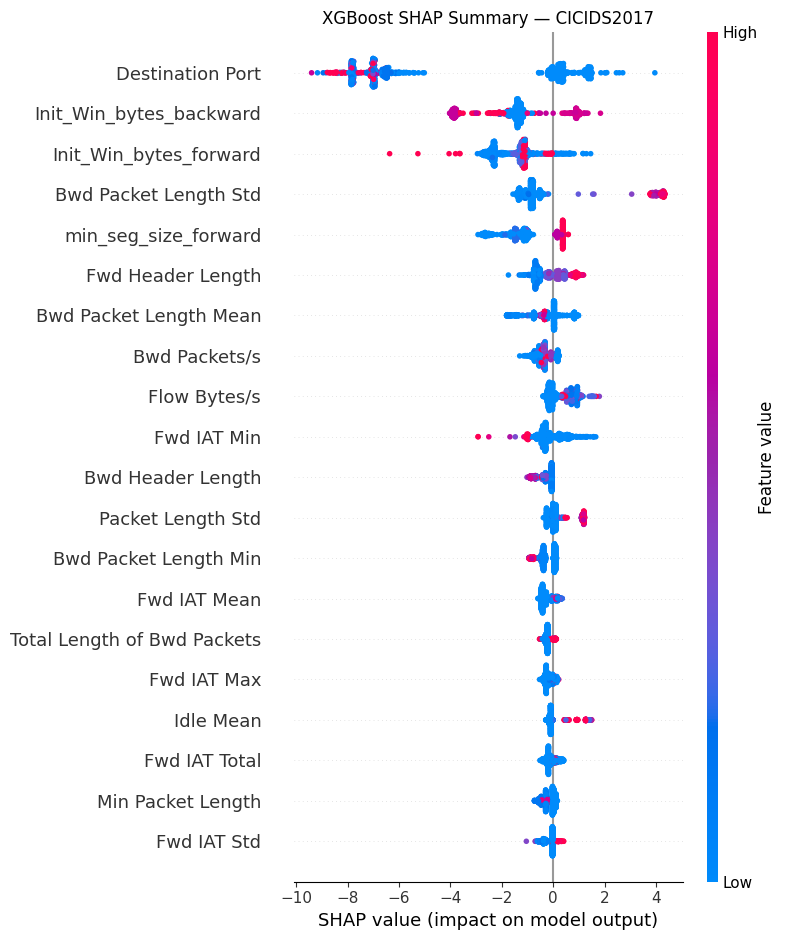

In [108]:
shap.summary_plot(
    shap_values_xgb.values,
    X_shap,
    feature_names=feature_cols,
    max_display=20,
    show=False
)

plt.title(
    "XGBoost SHAP Summary — CICIDS2017"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_beeswarm.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [109]:
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_Absolute_SHAP": np.abs(
        shap_values_xgb.values
    ).mean(axis=0)
})

importance_df = importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

importance_df.insert(
    0,
    "Rank",
    np.arange(1, len(importance_df) + 1)
)

print("Top 20 important network-flow features:")

display(importance_df.head(20))

importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_feature_importance.csv"
    ),
    index=False
)

Top 20 important network-flow features:


,Rank,Feature,Mean_Absolute_SHAP
0,1,Destination Port,4.221047
1,2,Init_Win_bytes_backward,1.873387
2,3,Init_Win_bytes_forward,1.594000
3,4,Bwd Packet Length Std,1.546323
4,5,min_seg_size_forward,1.172830
5,6,Fwd Header Length,0.530092
6,7,Bwd Packet Length Mean,0.468659
7,8,Bwd Packets/s,0.445677
8,9,Flow Bytes/s,0.433468
9,10,Fwd IAT Min,0.422486


In [110]:
ddos_indices = np.where(
    shap_sample_df["Label"].to_numpy() == "DDoS"
)[0]

ddos_index = int(ddos_indices[0])

print("Selected sample index:", ddos_index)

print(
    "Actual label:",
    shap_sample_df.iloc[ddos_index]["Label"]
)

ddos_probability = xgb_model.predict_proba(
    X_shap.iloc[[ddos_index]]
)[0, 1]

print(
    "Attack probability:",
    round(float(ddos_probability), 6)
)

Selected sample index: 400
Actual label: DDoS
Attack probability: 0.225059


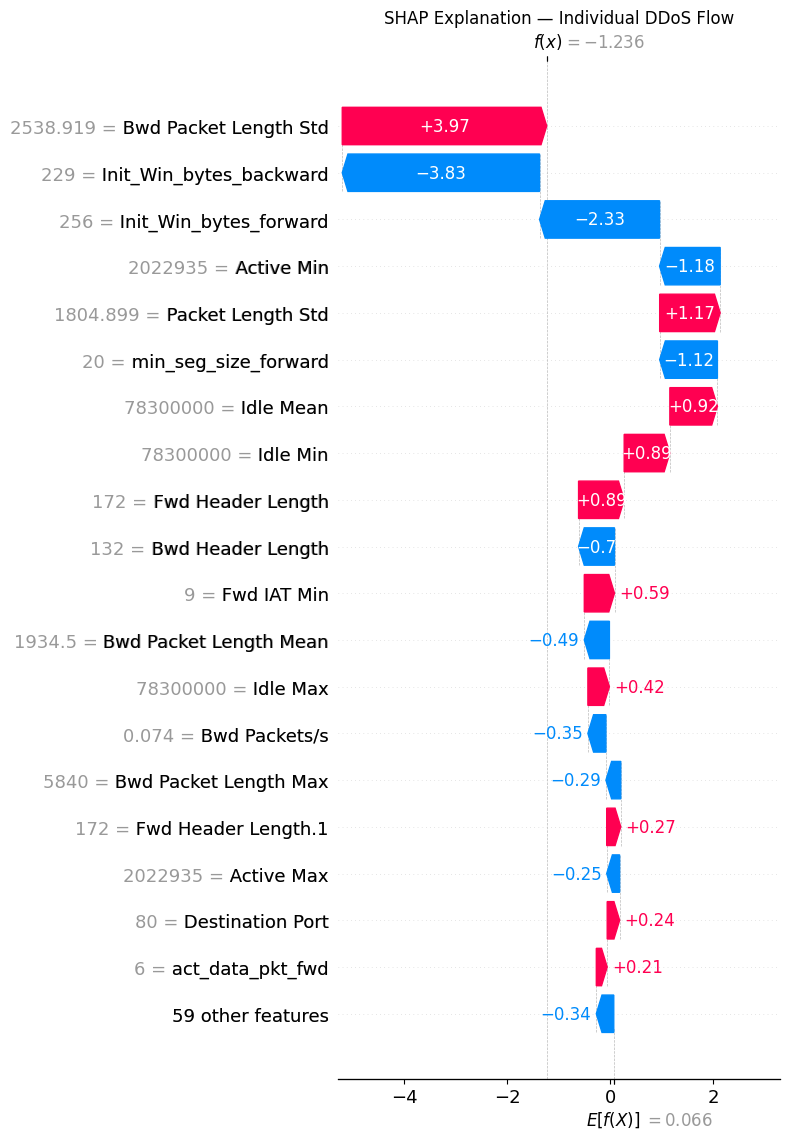

In [111]:
shap.plots.waterfall(
    shap_values_xgb[ddos_index],
    max_display=20,
    show=False
)

plt.title(
    "SHAP Explanation — Individual DDoS Flow"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_ddos_waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [112]:
attack_importance = {}

for attack in ["Bot", "DDoS", "PortScan"]:

    mask = (
        shap_sample_df["Label"].to_numpy()
        == attack
    )

    values = shap_values_xgb.values[mask]

    mean_importance = np.abs(values).mean(axis=0)

    attack_importance[attack] = mean_importance

attack_importance_df = pd.DataFrame(
    attack_importance,
    index=feature_cols
)

display(
    attack_importance_df.head(20)
)

attack_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_attack_comparison.csv"
    )
)

,Bot,DDoS,PortScan
Destination Port,6.673016,0.643895,7.239831
Flow Duration,0.086327,0.071540,0.200366
Total Fwd Packets,0.082786,0.066287,0.067082
Total Backward Packets,0.066771,0.060939,0.002237
Total Length of Fwd Packets,0.040045,0.024635,0.017715
Total Length of Bwd Packets,0.249589,0.134772,0.223818
Fwd Packet Length Max,0.076840,0.129087,0.059573
Fwd Packet Length Min,0.018093,0.016707,0.018774
Fwd Packet Length Mean,0.055780,0.103866,0.029616
Fwd Packet Length Std,0.077676,0.079819,0.044789


In [113]:
attack_importance = {}

for attack in ["Bot", "DDoS", "PortScan"]:

    mask = (
        shap_sample_df["Label"].to_numpy()
        == attack
    )

    values = shap_values_xgb.values[mask]

    mean_importance = np.abs(values).mean(axis=0)

    attack_importance[attack] = mean_importance

attack_importance_df = pd.DataFrame(
    attack_importance,
    index=feature_cols
)

display(
    attack_importance_df.head(20)
)

attack_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_attack_comparison.csv"
    )
)

,Bot,DDoS,PortScan
Destination Port,6.673016,0.643895,7.239831
Flow Duration,0.086327,0.071540,0.200366
Total Fwd Packets,0.082786,0.066287,0.067082
Total Backward Packets,0.066771,0.060939,0.002237
Total Length of Fwd Packets,0.040045,0.024635,0.017715
Total Length of Bwd Packets,0.249589,0.134772,0.223818
Fwd Packet Length Max,0.076840,0.129087,0.059573
Fwd Packet Length Min,0.018093,0.016707,0.018774
Fwd Packet Length Mean,0.055780,0.103866,0.029616
Fwd Packet Length Std,0.077676,0.079819,0.044789


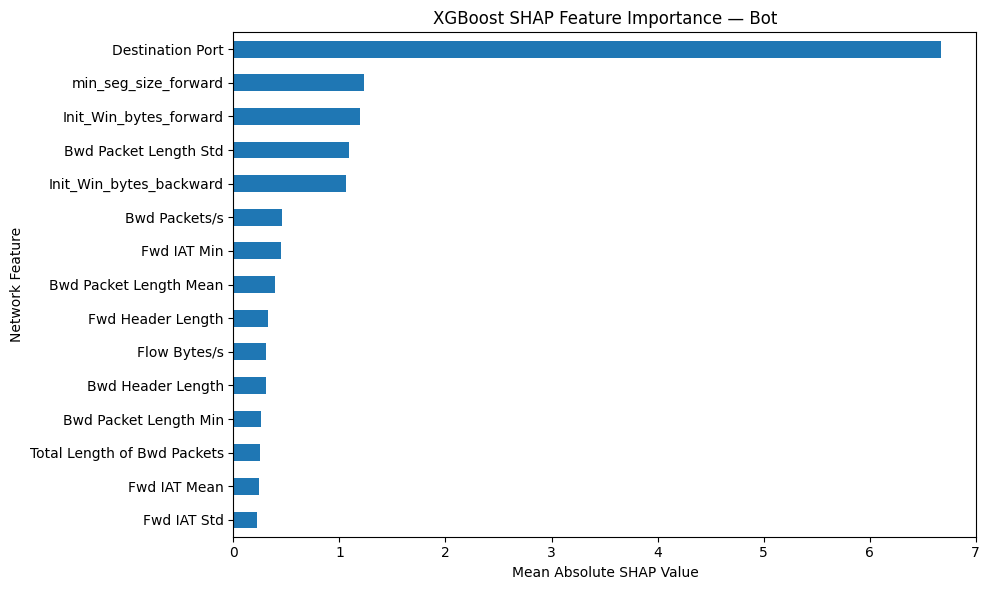

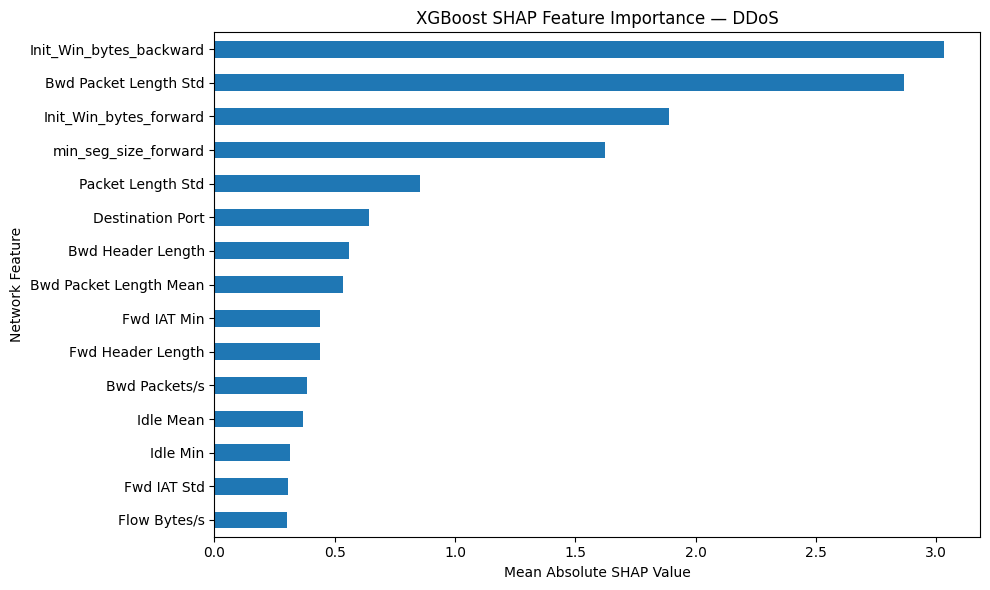

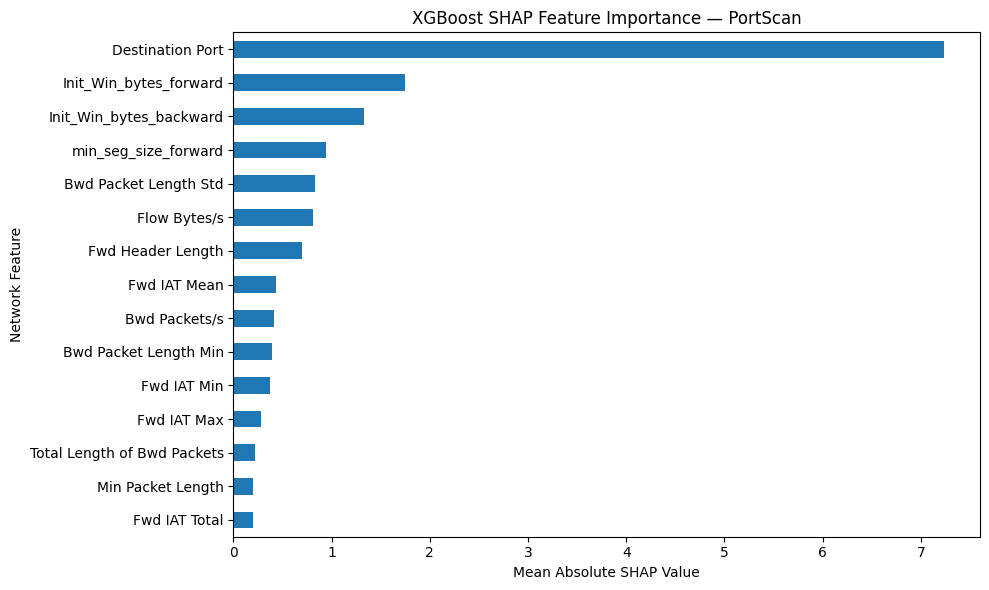

In [114]:
for attack in ["Bot", "DDoS", "PortScan"]:

    top_features = (
        attack_importance_df[attack]
        .sort_values(ascending=False)
        .head(15)
        .sort_values()
    )

    plt.figure(figsize=(10, 6))

    top_features.plot(kind="barh")

    plt.title(
        f"XGBoost SHAP Feature Importance — {attack}"
    )

    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Network Feature")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            SHAP_DIR,
            f"xgboost_shap_{attack.lower()}_importance.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [115]:
print("SHAP output directory:")
print(SHAP_DIR)

print("\nSaved files:")

for filename in sorted(os.listdir(SHAP_DIR)):
    print(filename)

SHAP output directory:
/content/drive/MyDrive/NIDS_Project/SHAP_Results

Saved files:
xgboost_shap_attack_comparison.csv
xgboost_shap_beeswarm.png
xgboost_shap_bot_importance.png
xgboost_shap_ddos_importance.png
xgboost_shap_ddos_waterfall.png
xgboost_shap_feature_importance.csv
xgboost_shap_global_bar.png
xgboost_shap_portscan_importance.png


In [116]:
shap_predictions = (
    xgb_model.predict_proba(X_shap)[:, 1]
    >= best_threshold
).astype(int)

actual_labels = shap_sample_df[
    "Binary_Label"
].to_numpy()

shap_sample_df["Prediction"] = shap_predictions

shap_sample_df["Outcome"] = np.select(
    [
        (actual_labels == 1) & (shap_predictions == 1),
        (actual_labels == 1) & (shap_predictions == 0),
        (actual_labels == 0) & (shap_predictions == 1),
        (actual_labels == 0) & (shap_predictions == 0)
    ],
    ["TP", "FN", "FP", "TN"],
    default="Unknown"
)

print("Prediction outcomes:")
display(shap_sample_df["Outcome"].value_counts())

print("\nOutcomes by attack type:")
display(
    pd.crosstab(
        shap_sample_df["Label"],
        shap_sample_df["Outcome"]
    )
)

Prediction outcomes:


,count
Outcome,
FN,573
TN,250
TP,177



Outcomes by attack type:


Outcome,FN,TN,TP
Label,,,
BENIGN,0,250,0
Bot,150,0,0
DDoS,124,0,176
PortScan,299,0,1


In [117]:
shap_values_array = shap_values_xgb.values

outcome_importance = {}

for outcome in ["TP", "FN", "FP", "TN"]:

    mask = (
        shap_sample_df["Outcome"].to_numpy()
        == outcome
    )

    if mask.sum() == 0:
        continue

    outcome_importance[outcome] = (
        np.abs(shap_values_array[mask]).mean(axis=0)
    )

outcome_importance_df = pd.DataFrame(
    outcome_importance,
    index=feature_cols
)

display(
    outcome_importance_df.head(20)
)

outcome_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "xgboost_shap_prediction_outcomes.csv"
    )
)

,TP,FN,TN
Destination Port,0.314352,5.777366,3.419909
Flow Duration,0.078063,0.140844,0.070724
Total Fwd Packets,0.060479,0.072816,0.087709
Total Backward Packets,0.086313,0.023894,0.150773
Total Length of Fwd Packets,0.029959,0.023402,0.037596
Total Length of Bwd Packets,0.062145,0.233884,0.282787
Fwd Packet Length Max,0.100042,0.087987,0.152973
Fwd Packet Length Min,0.006174,0.021406,0.023539
Fwd Packet Length Mean,0.148938,0.038481,0.092306
Fwd Packet Length Std,0.067921,0.064593,0.080707


In [118]:
import numpy as np
import pandas as pd

labels = shap_sample_df["Label"].to_numpy()
outcomes = shap_sample_df["Outcome"].to_numpy()

ddos_tp_mask = (labels == "DDoS") & (outcomes == "TP")
ddos_fn_mask = (labels == "DDoS") & (outcomes == "FN")

ddos_tp_importance = np.abs(
    shap_values_xgb.values[ddos_tp_mask]
).mean(axis=0)

ddos_fn_importance = np.abs(
    shap_values_xgb.values[ddos_fn_mask]
).mean(axis=0)

ddos_comparison = pd.DataFrame({
    "Feature": feature_cols,
    "Detected_DDoS": ddos_tp_importance,
    "Missed_DDoS": ddos_fn_importance
})

ddos_comparison["Difference"] = (
    ddos_comparison["Detected_DDoS"]
    - ddos_comparison["Missed_DDoS"]
)

ddos_comparison = ddos_comparison.sort_values(
    "Difference",
    key=abs,
    ascending=False
)

display(ddos_comparison.head(20))

ddos_comparison.to_csv(
    os.path.join(
        SHAP_DIR,
        "xgboost_ddos_detected_vs_missed.csv"
    ),
    index=False
)

,Feature,Detected_DDoS,Missed_DDoS,Difference
13,Bwd Packet Length Std,4.053321,1.183844,2.869478
67,Init_Win_bytes_backward,3.829077,1.896222,1.932854
69,min_seg_size_forward,1.127244,2.325852,-1.198609
66,Init_Win_bytes_forward,1.539162,2.387055,-0.847893
0,Destination Port,0.293659,1.141003,-0.847344
41,Packet Length Std,1.158314,0.424599,0.733715
35,Bwd Header Length,0.800438,0.213123,0.587315
38,Min Packet Length,0.029472,0.417005,-0.387534
12,Bwd Packet Length Mean,0.378530,0.751099,-0.372569
34,Fwd Header Length,0.558920,0.266605,0.292315


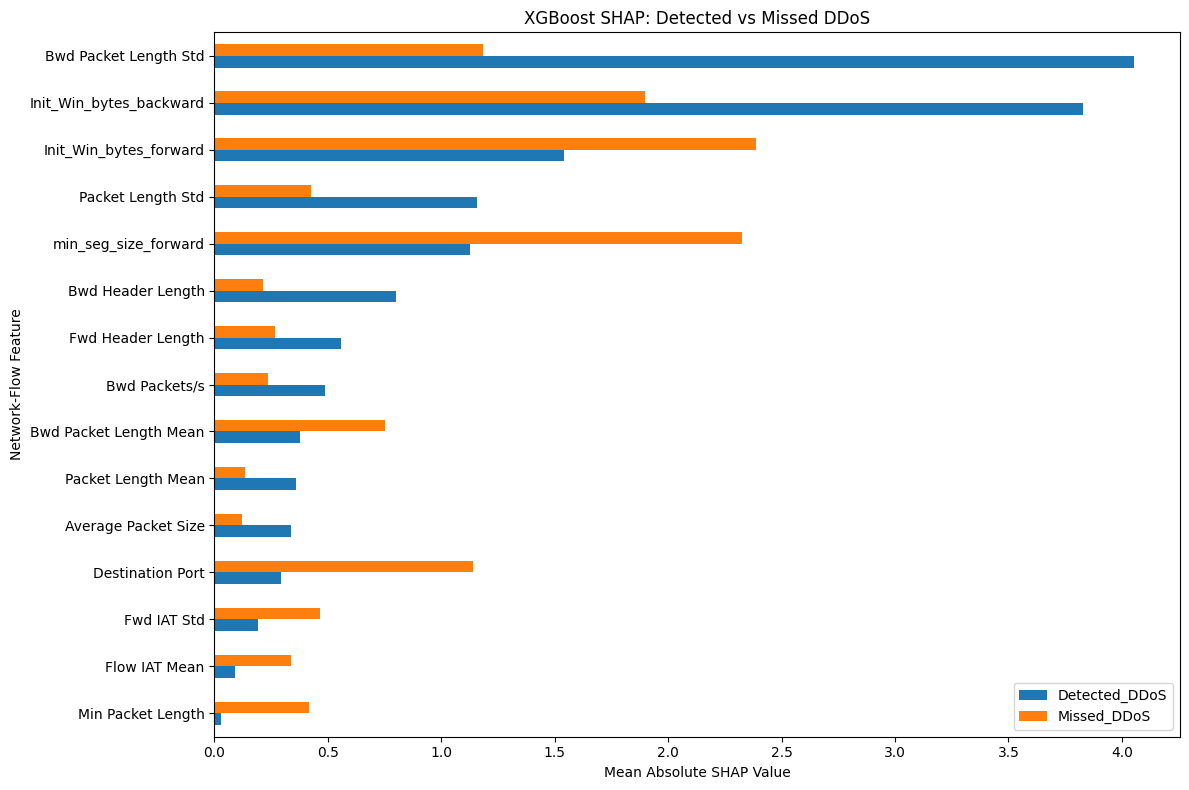

In [119]:
import matplotlib.pyplot as plt

top_ddos = ddos_comparison.head(15).copy()

top_ddos = top_ddos.set_index("Feature")

top_ddos[
    ["Detected_DDoS", "Missed_DDoS"]
].sort_values(
    "Detected_DDoS"
).plot(
    kind="barh",
    figsize=(12, 8)
)

plt.title(
    "XGBoost SHAP: Detected vs Missed DDoS"
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Network-Flow Feature")

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_DIR,
        "xgboost_ddos_detected_vs_missed.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [120]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import shap
import time
import matplotlib.pyplot as plt

LSTM_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "lstm_binary_best.keras"
)

lstm_model = tf.keras.models.load_model(
    LSTM_PATH,
    compile=False
)

print("LSTM model loaded successfully!")
lstm_model.summary()

LSTM model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
rng = np.random.default_rng(42)

# Small background sample from training data
background_idx = rng.choice(
    len(X_train_lstm),
    size=min(30, len(X_train_lstm)),
    replace=False
)

background_lstm = (
    X_train_lstm[background_idx]
    .reshape(-1, 78)
    .astype(np.float32)
)

# Select 60 representative test records
sample_idx = rng.choice(
    len(X_test_lstm),
    size=min(60, len(X_test_lstm)),
    replace=False
)

X_explain_lstm = (
    X_test_lstm[sample_idx]
    .reshape(-1, 78)
    .astype(np.float32)
)

print("Background shape:", background_lstm.shape)
print("Explanation sample shape:", X_explain_lstm.shape)

Background shape: (30, 78)
Explanation sample shape: (60, 78)


In [122]:
def lstm_predict_shap(X):

    X = np.asarray(
        X,
        dtype=np.float32
    )

    X = X.reshape(
        -1,
        78,
        1
    )

    probabilities = lstm_model.predict(
        X,
        batch_size=1024,
        verbose=0
    )

    return probabilities.ravel()

In [123]:
test_predictions = lstm_predict_shap(
    X_explain_lstm[:5]
)

print("Sample LSTM probabilities:")
print(test_predictions)

Sample LSTM probabilities:
[5.0538190e-05 1.7543953e-05 1.9175364e-05 4.5431202e-04 3.0961080e-05]


In [124]:
masker = shap.maskers.Independent(
    background_lstm
)

explainer_lstm = shap.Explainer(
    lstm_predict_shap,
    masker,
    algorithm="permutation",
    feature_names=list(feature_cols)
)

print("LSTM SHAP explainer initialized!")

LSTM SHAP explainer initialized!


In [125]:
start_time = time.perf_counter()

shap_values_lstm = explainer_lstm(
    X_explain_lstm[:5],
    max_evals=2 * 78 + 1
)

elapsed_time = time.perf_counter() - start_time

print("LSTM SHAP calculation completed!")

print(
    "SHAP shape:",
    shap_values_lstm.values.shape
)

print(
    "Total explanation time:",
    round(elapsed_time, 2),
    "seconds"
)

print(
    "Average time per record:",
    round(elapsed_time / 5, 3),
    "seconds"
)

LSTM SHAP calculation completed!
SHAP shape: (5, 78)
Total explanation time: 4.64 seconds
Average time per record: 0.929 seconds


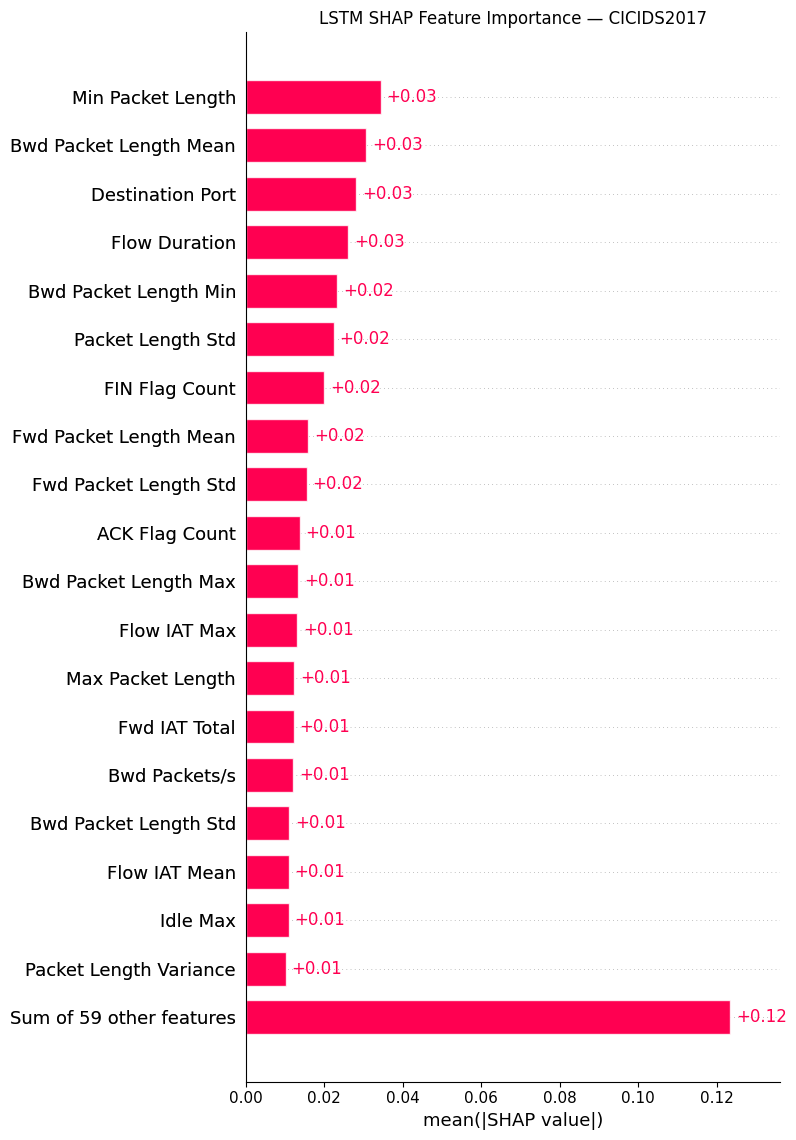

In [126]:
shap.plots.bar(
    shap_values_lstm,
    max_display=20,
    show=False
)

plt.title(
    "LSTM SHAP Feature Importance — CICIDS2017"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_DIR,
        "lstm_shap_initial_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

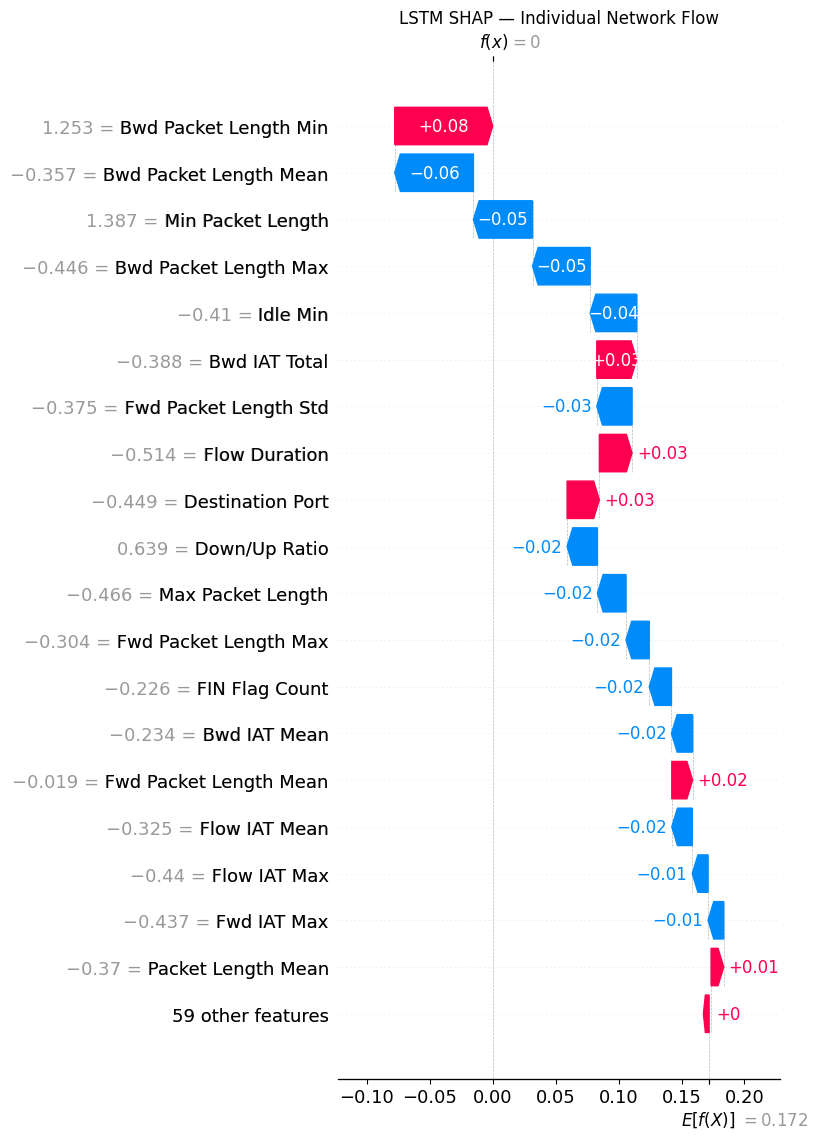

In [127]:
shap.plots.waterfall(
    shap_values_lstm[0],
    max_display=20,
    show=False
)

plt.title(
    "LSTM SHAP — Individual Network Flow"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_DIR,
        "lstm_shap_initial_waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [128]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

labels = test_df["Label"].astype(str).str.strip().to_numpy()

assert len(labels) == len(X_test_lstm), (
    "Test labels and LSTM features are not aligned."
)

sample_indices = []

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    indices = np.where(labels == attack)[0]

    if len(indices) == 0:
        raise ValueError(f"No records found for {attack}")

    selected = rng.choice(
        indices,
        size=min(20, len(indices)),
        replace=False
    )

    sample_indices.extend(selected)

sample_indices = np.array(sample_indices)

X_lstm_attack_sample = (
    X_test_lstm[sample_indices]
    .reshape(-1, 78)
    .astype(np.float32)
)

attack_labels_sample = labels[sample_indices]

print("Sample shape:", X_lstm_attack_sample.shape)

print("\nAttack distribution:")
print(pd.Series(attack_labels_sample).value_counts())

Sample shape: (80, 78)

Attack distribution:
BENIGN      20
Bot         20
DDoS        20
PortScan    20
Name: count, dtype: int64


In [129]:
import time

start_time = time.perf_counter()

shap_values_lstm_attack = explainer_lstm(
    X_lstm_attack_sample,
    max_evals=2 * 78 + 1
)

elapsed = time.perf_counter() - start_time

print("Attack-specific SHAP completed!")

print(
    "SHAP shape:",
    shap_values_lstm_attack.values.shape
)

print(
    "Total time:",
    round(elapsed, 2),
    "seconds"
)

print(
    "Average time per sample:",
    round(elapsed / len(X_lstm_attack_sample), 3),
    "seconds"
)

PermutationExplainer explainer: 81it [00:40,  1.55it/s]

Attack-specific SHAP completed!
SHAP shape: (80, 78)
Total time: 40.76 seconds
Average time per sample: 0.51 seconds


In [130]:
import time

start_time = time.perf_counter()

shap_values_lstm_attack = explainer_lstm(
    X_lstm_attack_sample,
    max_evals=2 * 78 + 1
)

elapsed = time.perf_counter() - start_time

print("Attack-specific SHAP completed!")

print(
    "SHAP shape:",
    shap_values_lstm_attack.values.shape
)

print(
    "Total time:",
    round(elapsed, 2),
    "seconds"
)

print(
    "Average time per sample:",
    round(elapsed / len(X_lstm_attack_sample), 3),
    "seconds"
)

PermutationExplainer explainer: 81it [00:37,  1.50it/s]

Attack-specific SHAP completed!
SHAP shape: (80, 78)
Total time: 37.88 seconds
Average time per sample: 0.474 seconds


In [131]:
attack_importance_lstm = {}

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    values = shap_values_lstm_attack.values[mask]

    mean_importance = np.abs(values).mean(axis=0)

    attack_importance_lstm[attack] = mean_importance

lstm_attack_importance_df = pd.DataFrame(
    attack_importance_lstm,
    index=feature_cols
)

print("Attack-specific LSTM SHAP importance:")

display(lstm_attack_importance_df.head(20))

Attack-specific LSTM SHAP importance:


,BENIGN,Bot,DDoS,PortScan
Destination Port,0.028793,0.035897,0.039645,0.038137
Flow Duration,0.047183,0.023029,0.127496,0.044241
Total Fwd Packets,0.000837,0.000974,0.001891,0.000934
Total Backward Packets,0.000785,0.000642,0.000740,0.000286
Total Length of Fwd Packets,0.008427,0.006077,0.006484,0.004345
Total Length of Bwd Packets,0.000438,0.000049,0.000934,0.000136
Fwd Packet Length Max,0.030522,0.011390,0.018342,0.015574
Fwd Packet Length Min,0.012894,0.018751,0.046599,0.008911
Fwd Packet Length Mean,0.013722,0.011494,0.021523,0.010134
Fwd Packet Length Std,0.009878,0.017029,0.021314,0.013023


In [132]:
for attack in ["Bot", "DDoS", "PortScan"]:

    print("\n" + "=" * 50)
    print("Attack:", attack)
    print("=" * 50)

    top_features = (
        lstm_attack_importance_df[attack]
        .sort_values(ascending=False)
        .head(10)
    )

    display(
        top_features.reset_index().rename(
            columns={
                "index": "Feature",
                attack: "Mean Absolute SHAP"
            }
        )
    )


Attack: Bot


,Feature,Mean Absolute SHAP
0,Min Packet Length,0.039574
1,Destination Port,0.035897
2,Flow Duration,0.023029
3,Bwd Packet Length Std,0.022114
4,Bwd Packet Length Max,0.019622
5,Packet Length Mean,0.019355
6,Bwd Packet Length Mean,0.019182
7,Bwd Packet Length Min,0.019006
8,Fwd Packet Length Min,0.018751
9,Fwd Packet Length Std,0.017029



Attack: DDoS


,Feature,Mean Absolute SHAP
0,Flow Duration,0.127496
1,Max Packet Length,0.077698
2,Bwd Packet Length Mean,0.074309
3,Bwd Packet Length Min,0.072025
4,Packet Length Std,0.068889
5,Bwd Packet Length Max,0.062939
6,Packet Length Mean,0.052283
7,Fwd IAT Std,0.048429
8,Flow IAT Mean,0.048238
9,Fwd Packet Length Min,0.046599



Attack: PortScan


,Feature,Mean Absolute SHAP
0,Flow Duration,0.044241
1,Destination Port,0.038137
2,Min Packet Length,0.031992
3,Bwd Packet Length Mean,0.028069
4,Bwd Packet Length Min,0.024811
5,Bwd Packets/s,0.022778
6,ACK Flag Count,0.021335
7,Bwd Packet Length Std,0.020881
8,Packet Length Std,0.018474
9,Bwd Packet Length Max,0.017367


In [133]:
for attack in ["Bot", "DDoS", "PortScan"]:

    print("\n" + "=" * 50)
    print("Attack:", attack)
    print("=" * 50)

    top_features = (
        lstm_attack_importance_df[attack]
        .sort_values(ascending=False)
        .head(10)
    )

    display(
        top_features.reset_index().rename(
            columns={
                "index": "Feature",
                attack: "Mean Absolute SHAP"
            }
        )
    )


Attack: Bot


,Feature,Mean Absolute SHAP
0,Min Packet Length,0.039574
1,Destination Port,0.035897
2,Flow Duration,0.023029
3,Bwd Packet Length Std,0.022114
4,Bwd Packet Length Max,0.019622
5,Packet Length Mean,0.019355
6,Bwd Packet Length Mean,0.019182
7,Bwd Packet Length Min,0.019006
8,Fwd Packet Length Min,0.018751
9,Fwd Packet Length Std,0.017029



Attack: DDoS


,Feature,Mean Absolute SHAP
0,Flow Duration,0.127496
1,Max Packet Length,0.077698
2,Bwd Packet Length Mean,0.074309
3,Bwd Packet Length Min,0.072025
4,Packet Length Std,0.068889
5,Bwd Packet Length Max,0.062939
6,Packet Length Mean,0.052283
7,Fwd IAT Std,0.048429
8,Flow IAT Mean,0.048238
9,Fwd Packet Length Min,0.046599



Attack: PortScan


,Feature,Mean Absolute SHAP
0,Flow Duration,0.044241
1,Destination Port,0.038137
2,Min Packet Length,0.031992
3,Bwd Packet Length Mean,0.028069
4,Bwd Packet Length Min,0.024811
5,Bwd Packets/s,0.022778
6,ACK Flag Count,0.021335
7,Bwd Packet Length Std,0.020881
8,Packet Length Std,0.018474
9,Bwd Packet Length Max,0.017367


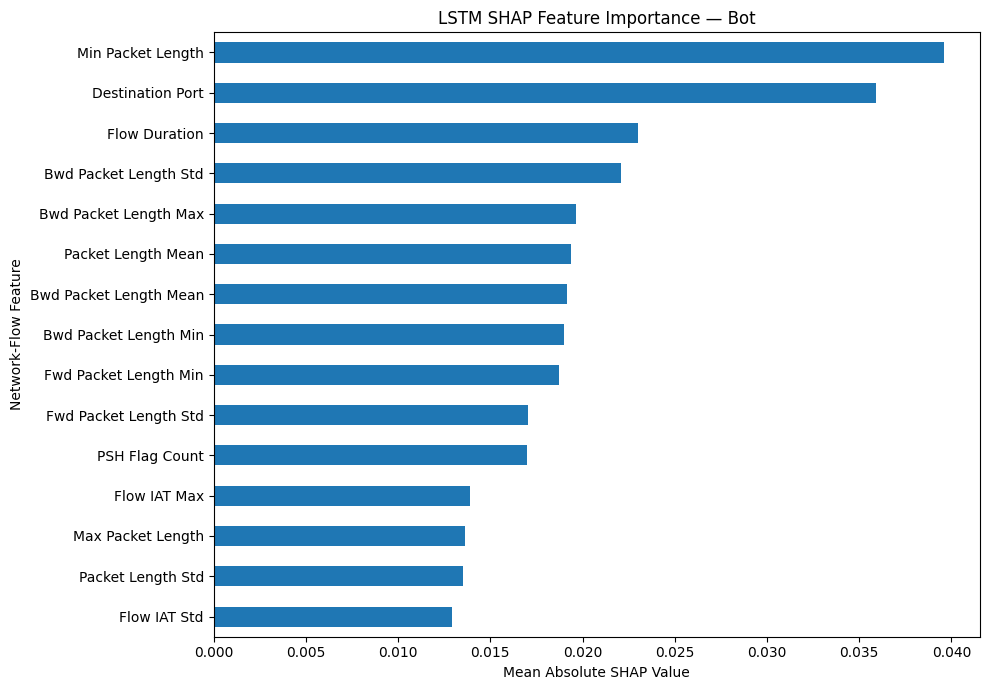

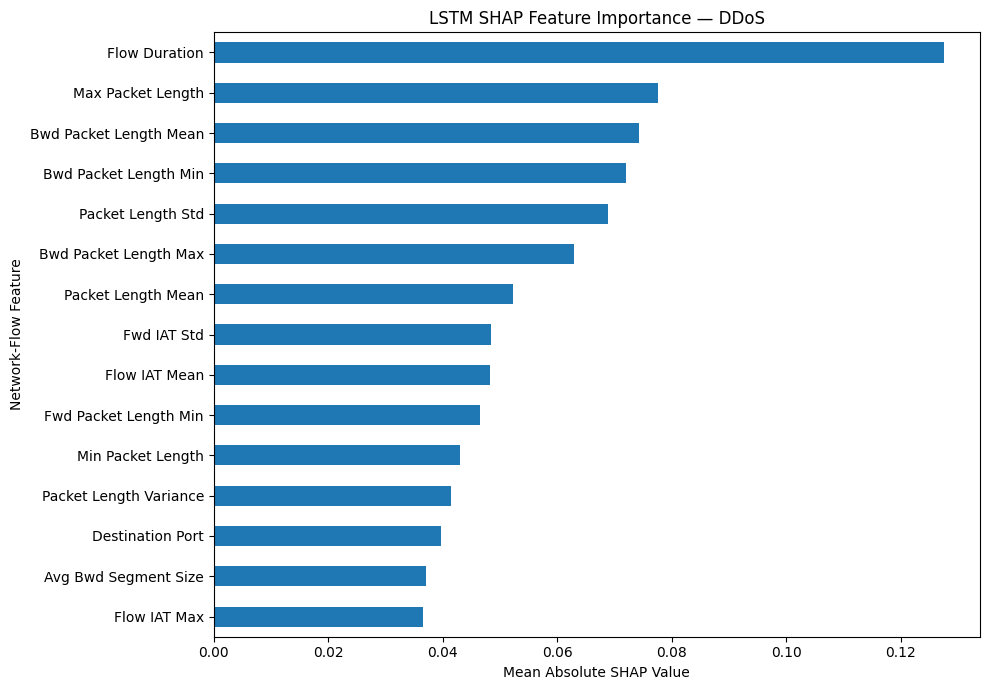

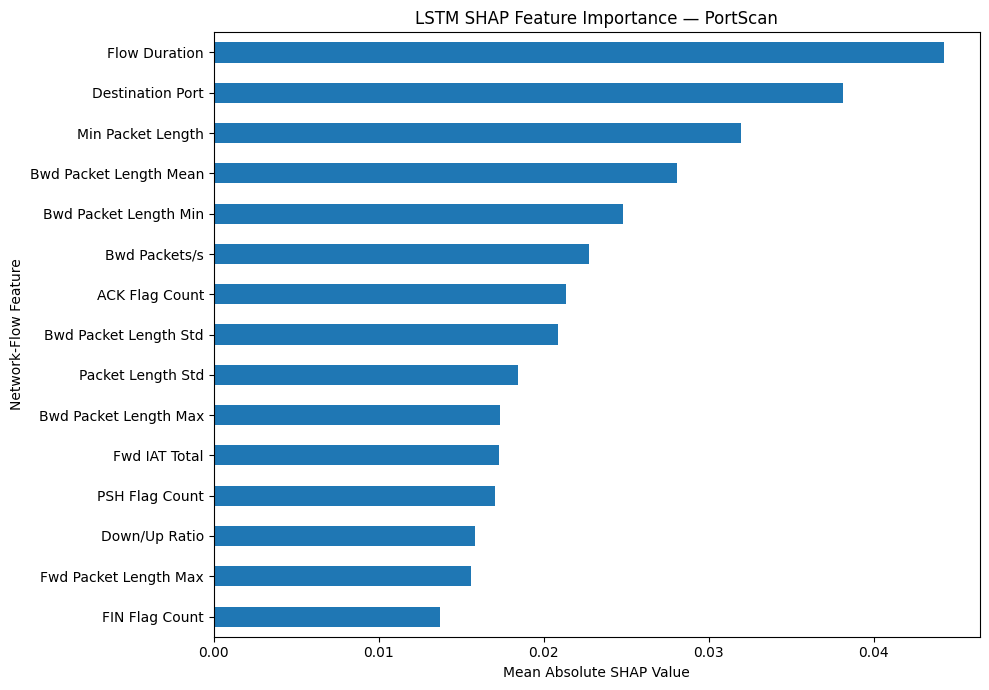

In [134]:
import matplotlib.pyplot as plt
import os

for attack in ["Bot", "DDoS", "PortScan"]:

    top_features = (
        lstm_attack_importance_df[attack]
        .sort_values(ascending=False)
        .head(15)
        .sort_values()
    )

    plt.figure(figsize=(10, 7))

    top_features.plot(
        kind="barh"
    )

    plt.title(
        f"LSTM SHAP Feature Importance — {attack}"
    )

    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Network-Flow Feature")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            SHAP_DIR,
            f"lstm_shap_{attack.lower()}_importance.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [135]:
from scipy.stats import spearmanr

xgb_importance = importance_df.set_index("Feature")[
    "Mean_Absolute_SHAP"
]

lstm_importance = (
    np.abs(shap_values_lstm_attack.values)
    .mean(axis=0)
)

comparison_df = pd.DataFrame({
    "Feature": feature_cols,
    "XGBoost_SHAP": [
        xgb_importance.loc[f] for f in feature_cols
    ],
    "LSTM_SHAP": lstm_importance
})

comparison_df["XGBoost_Rank"] = (
    comparison_df["XGBoost_SHAP"]
    .rank(ascending=False)
)

comparison_df["LSTM_Rank"] = (
    comparison_df["LSTM_SHAP"]
    .rank(ascending=False)
)

correlation, p_value = spearmanr(
    comparison_df["XGBoost_Rank"],
    comparison_df["LSTM_Rank"]
)

print("Spearman rank correlation:", correlation)
print("P-value:", p_value)

display(
    comparison_df.sort_values(
        "LSTM_Rank"
    ).head(20)
)

Spearman rank correlation: 0.503407663117282
P-value: 2.630192120446016e-06


,Feature,XGBoost_SHAP,LSTM_SHAP,XGBoost_Rank,LSTM_Rank
1,Flow Duration,0.112202,0.060487,30.0,1.0
38,Min Packet Length,0.175574,0.040138,19.0,2.0
12,Bwd Packet Length Mean,0.468659,0.036975,7.0,3.0
0,Destination Port,4.221047,0.035618,1.0,4.0
11,Bwd Packet Length Min,0.288748,0.034643,13.0,5.0
41,Packet Length Std,0.322053,0.030993,12.0,6.0
10,Bwd Packet Length Max,0.149404,0.030895,23.0,7.0
39,Max Packet Length,0.035947,0.029454,51.0,8.0
40,Packet Length Mean,0.135419,0.026262,26.0,9.0
13,Bwd Packet Length Std,1.546323,0.024886,4.0,10.0


In [136]:
os.makedirs(SHAP_DIR, exist_ok=True)

lstm_attack_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "lstm_attack_specific_shap.csv"
    )
)

comparison_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "xgboost_lstm_shap_comparison.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        SHAP_DIR,
        "lstm_attack_shap_values.npy"
    ),
    shap_values_lstm_attack.values
)

print("LSTM attack-specific SHAP results saved!")

LSTM attack-specific SHAP results saved!


In [137]:
import numpy as np
import pandas as pd

shap_reconstructed = (
    np.asarray(shap_values_lstm_attack.base_values).reshape(-1)
    + shap_values_lstm_attack.values.sum(axis=1)
)

actual_predictions = lstm_predict_shap(
    X_lstm_attack_sample
)

reconstruction_error = np.abs(
    actual_predictions - shap_reconstructed
)

fidelity_results = pd.DataFrame({
    "Actual_Prediction": actual_predictions,
    "SHAP_Reconstructed": shap_reconstructed,
    "Absolute_Error": reconstruction_error,
    "Attack_Type": attack_labels_sample
})

print("LSTM SHAP reconstruction fidelity:")

print(
    "Mean absolute error:",
    reconstruction_error.mean()
)

print(
    "Maximum absolute error:",
    reconstruction_error.max()
)

display(fidelity_results.head(10))

LSTM SHAP reconstruction fidelity:
Mean absolute error: 2.2997877911767883e-08
Maximum absolute error: 1.8143123270419892e-06


,Actual_Prediction,SHAP_Reconstructed,Absolute_Error,Attack_Type
0,0.000164,0.000164,3.638201e-13,BENIGN
1,0.815173,0.815173,1.333933e-12,BENIGN
2,0.000019,0.000019,2.775558e-17,BENIGN
3,0.000058,0.000058,2.425005e-13,BENIGN
4,0.000017,0.000017,2.775558e-17,BENIGN
5,0.000011,0.000011,2.728373e-13,BENIGN
6,0.000734,0.000734,9.098278e-14,BENIGN
7,0.000031,0.000031,4.243550e-13,BENIGN
8,0.000028,0.000028,2.775558e-17,BENIGN
9,0.000060,0.000060,0.000000e+00,BENIGN


In [138]:
from sklearn.metrics.pairwise import cosine_similarity

consistency_results = []

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    attack_shap = (
        shap_values_lstm_attack.values[mask]
    )

    similarity_matrix = cosine_similarity(
        attack_shap
    )

    upper_indices = np.triu_indices(
        len(attack_shap),
        k=1
    )

    mean_similarity = (
        similarity_matrix[upper_indices].mean()
    )

    consistency_results.append({
        "Attack": attack,
        "Samples": len(attack_shap),
        "Mean_Cosine_Similarity": mean_similarity
    })

consistency_df = pd.DataFrame(
    consistency_results
)

display(consistency_df)

,Attack,Samples,Mean_Cosine_Similarity
0,BENIGN,20,0.076340
1,Bot,20,0.290465
2,DDoS,20,0.049905
3,PortScan,20,0.318018


In [139]:
import os

EVAL_DIR = os.path.join(
    RESULT_DIR,
    "shap",
    "evaluation"
)

os.makedirs(EVAL_DIR, exist_ok=True)

fidelity_results.to_csv(
    os.path.join(
        EVAL_DIR,
        "lstm_shap_fidelity.csv"
    ),
    index=False
)

consistency_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "lstm_shap_consistency.csv"
    ),
    index=False
)

latency_df = pd.DataFrame([{
    "Model": "LSTM",
    "Samples": len(X_lstm_attack_sample),
    "Total_Seconds": elapsed,
    "Seconds_Per_Sample": elapsed / len(X_lstm_attack_sample)
}])

latency_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "lstm_shap_latency.csv"
    ),
    index=False
)

print("SHAP evaluation results saved successfully!")

SHAP evaluation results saved successfully!


In [140]:
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import (
    cosine_similarity,
    euclidean_distances
)

X_features = X_lstm_attack_sample
shap_values = shap_values_lstm_attack.values

local_results = []

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    X_group = X_features[mask]
    SHAP_group = shap_values[mask]

    distances = euclidean_distances(X_group)

    np.fill_diagonal(distances, np.inf)

    nearest_indices = np.argmin(distances, axis=1)

    feature_distances = distances[
        np.arange(len(X_group)),
        nearest_indices
    ]

    explanation_similarities = []

    for i, j in enumerate(nearest_indices):

        similarity = cosine_similarity(
            SHAP_group[i].reshape(1, -1),
            SHAP_group[j].reshape(1, -1)
        )[0, 0]

        explanation_similarities.append(similarity)

    local_results.append({
        "Attack": attack,
        "Samples": len(X_group),
        "Mean_Nearest_Feature_Distance": np.mean(
            feature_distances
        ),
        "Mean_Local_SHAP_Similarity": np.mean(
            explanation_similarities
        )
    })

local_consistency_df = pd.DataFrame(local_results)

display(local_consistency_df)

,Attack,Samples,Mean_Nearest_Feature_Distance,Mean_Local_SHAP_Similarity
0,BENIGN,20,3.325908,0.265910
1,Bot,20,0.383085,0.317432
2,DDoS,20,2.169326,0.337865
3,PortScan,20,0.402104,0.383967


In [141]:
consistency_comparison = consistency_df.merge(
    local_consistency_df,
    on=["Attack", "Samples"]
)

display(consistency_comparison)

consistency_comparison.to_csv(
    os.path.join(
        EVAL_DIR,
        "lstm_global_local_consistency.csv"
    ),
    index=False
)

,Attack,Samples,Mean_Cosine_Similarity,Mean_Nearest_Feature_Distance,Mean_Local_SHAP_Similarity
0,BENIGN,20,0.076340,3.325908,0.265910
1,Bot,20,0.290465,0.383085,0.317432
2,DDoS,20,0.049905,2.169326,0.337865
3,PortScan,20,0.318018,0.402104,0.383967


In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_eval = X_lstm_attack_sample.copy()

shap_eval = shap_values_lstm_attack.values

labels_eval = np.asarray(attack_labels_sample)

assert X_eval.shape == shap_eval.shape
assert X_eval.shape[1] == 78

# Original model probabilities
original_prob = lstm_predict_shap(X_eval)

print("Evaluation samples:", len(X_eval))
print("Features:", X_eval.shape[1])
print("Original probability range:",
      original_prob.min(), original_prob.max())

Evaluation samples: 80
Features: 78
Original probability range: 1.09083585e-05 0.99999136


In [143]:
rng = np.random.default_rng(42)

background = np.asarray(
    background_lstm,
    dtype=np.float32
)

def perturb_features(X, shap_values, k, method="top"):

    X_modified = X.copy()

    for i in range(len(X_modified)):

        if method == "top":
            selected = np.argsort(
                np.abs(shap_values[i])
            )[-k:]

        elif method == "random":
            selected = rng.choice(
                X_modified.shape[1],
                size=k,
                replace=False
            )

        else:
            raise ValueError("Unknown perturbation method")

        # Use a training-background record
        background_row = background[
            rng.integers(len(background))
        ]

        X_modified[i, selected] = background_row[selected]

    return X_modified

In [144]:
perturbation_results = []

for k in [1, 5, 10, 20]:

    for method in ["top", "random"]:

        X_modified = perturb_features(
            X_eval,
            shap_eval,
            k,
            method
        )

        modified_prob = lstm_predict_shap(
            X_modified
        )

        mean_change = np.mean(
            np.abs(original_prob - modified_prob)
        )

        perturbation_results.append({
            "Features_Removed": k,
            "Method": method,
            "Mean_Absolute_Probability_Change": mean_change
        })

perturbation_df = pd.DataFrame(
    perturbation_results
)

display(perturbation_df)

,Features_Removed,Method,Mean_Absolute_Probability_Change
0,1,top,0.050468
1,1,random,0.003365
2,5,top,0.060951
3,5,random,0.035485
4,10,top,0.104585
5,10,random,0.077840
6,20,top,0.110415
7,20,random,0.106986


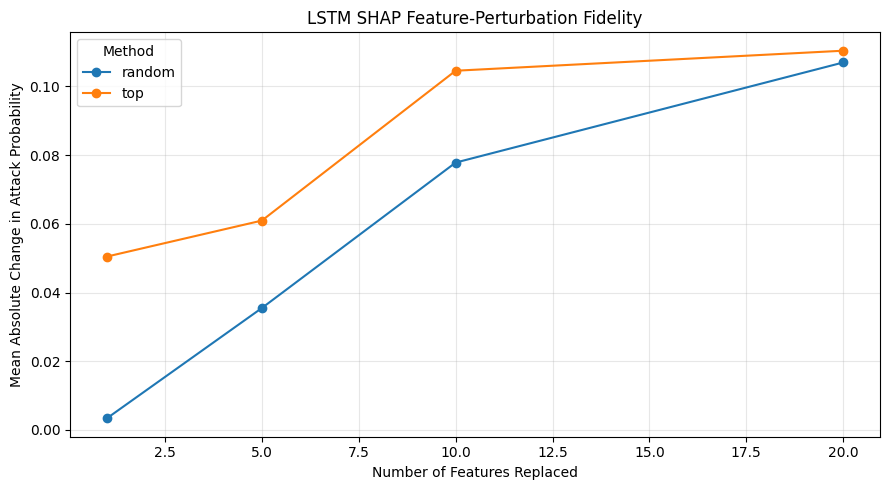

In [145]:
pivot_df = perturbation_df.pivot(
    index="Features_Removed",
    columns="Method",
    values="Mean_Absolute_Probability_Change"
)

pivot_df.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("LSTM SHAP Feature-Perturbation Fidelity")
plt.xlabel("Number of Features Replaced")
plt.ylabel("Mean Absolute Change in Attack Probability")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [146]:
import os

os.makedirs(EVAL_DIR, exist_ok=True)

perturbation_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "lstm_shap_perturbation_fidelity.csv"
    ),
    index=False
)

print("Perturbation fidelity results saved successfully!")

Perturbation fidelity results saved successfully!


In [147]:
import time
import numpy as np
import pandas as pd

batch_sizes = [1, 5, 10, 20, 40, 80]
repetitions = 3

latency_results = []

for batch_size in batch_sizes:

    X_batch = X_lstm_attack_sample[:batch_size]

    for run in range(repetitions):

        start = time.perf_counter()

        _ = explainer_lstm(
            X_batch,
            max_evals=2 * 78 + 1
        )

        elapsed = time.perf_counter() - start

        latency_results.append({
            "Batch_Size": batch_size,
            "Run": run + 1,
            "Total_Seconds": elapsed,
            "Seconds_Per_Record": elapsed / batch_size
        })

latency_raw_df = pd.DataFrame(latency_results)

latency_summary_df = (
    latency_raw_df.groupby("Batch_Size")
    .agg(
        Mean_Total_Seconds=("Total_Seconds", "mean"),
        Std_Total_Seconds=("Total_Seconds", "std"),
        Mean_Seconds_Per_Record=("Seconds_Per_Record", "mean")
    )
    .reset_index()
)

display(latency_summary_df)

PermutationExplainer explainer: 21it [00:10,  3.66s/it]
PermutationExplainer explainer: 41it [00:18,  1.02s/it]
PermutationExplainer explainer: 41it [00:24,  1.22it/s]
PermutationExplainer explainer: 41it [00:18,  1.02s/it]
PermutationExplainer explainer: 81it [00:35,  1.62it/s]
PermutationExplainer explainer: 81it [00:35,  1.62it/s]
PermutationExplainer explainer: 81it [00:34,  1.63it/s]


,Batch_Size,Mean_Total_Seconds,Std_Total_Seconds,Mean_Seconds_Per_Record
0,1,0.627569,0.191774,0.627569
1,5,2.871687,1.001327,0.574337
2,10,5.032426,0.964042,0.503243
3,20,9.509842,1.310560,0.475492
4,40,20.438075,3.670572,0.510952
5,80,35.288649,0.794491,0.441108


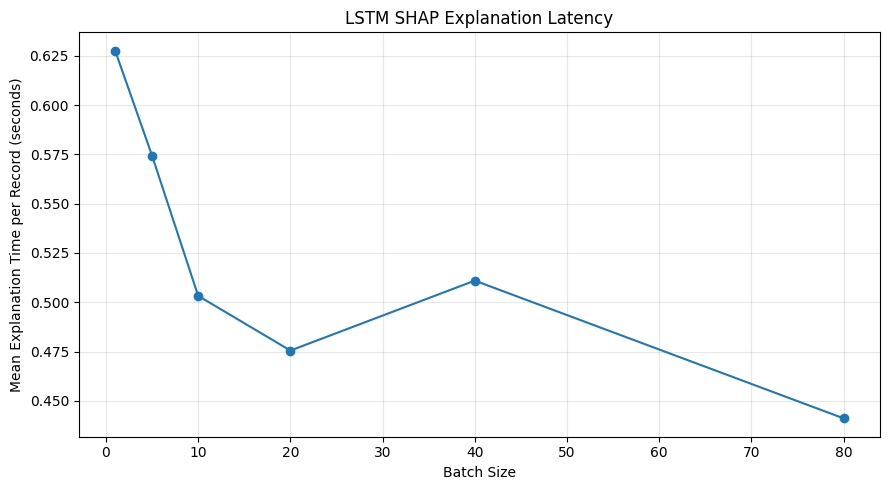

In [148]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    latency_summary_df["Batch_Size"],
    latency_summary_df["Mean_Seconds_Per_Record"],
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Mean Explanation Time per Record (seconds)")
plt.title("LSTM SHAP Explanation Latency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [149]:
import os

os.makedirs(EVAL_DIR, exist_ok=True)

latency_raw_df.to_csv(
    os.path.join(EVAL_DIR, "lstm_shap_latency_raw.csv"),
    index=False
)

latency_summary_df.to_csv(
    os.path.join(EVAL_DIR, "lstm_shap_latency_summary.csv"),
    index=False
)

print("LSTM SHAP latency results saved successfully!")

LSTM SHAP latency results saved successfully!


In [150]:
import os
import pandas as pd

final_comparison_df = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Macro F1": 0.677502,
        "Weighted F1": 0.719943,
        "Precision": 0.998668,
        "Recall": 0.347349,
        "ROC-AUC": 0.788191,
        "PR-AUC": 0.807211
    },
    {
        "Model": "1D-CNN",
        "Macro F1": 0.698048,
        "Weighted F1": 0.735142,
        "Precision": 0.912766,
        "Recall": 0.400159,
        "ROC-AUC": 0.755375,
        "PR-AUC": 0.748061
    },
    {
        "Model": "LSTM",
        "Macro F1": 0.824474,
        "Weighted F1": 0.834752,
        "Precision": 0.748358,
        "Recall": 0.825908,
        "ROC-AUC": 0.859919,
        "PR-AUC": 0.856631
    }
])

display(final_comparison_df)

os.makedirs(RESULT_DIR, exist_ok=True)

final_comparison_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_three_model_comparison.csv"
    ),
    index=False
)

print("Final model comparison saved successfully!")

,Model,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBoost,0.677502,0.719943,0.998668,0.347349,0.788191,0.807211
1,1D-CNN,0.698048,0.735142,0.912766,0.400159,0.755375,0.748061
2,LSTM,0.824474,0.834752,0.748358,0.825908,0.859919,0.856631


Final model comparison saved successfully!


In [151]:
import numpy as np
import shap
import time
import pandas as pd

def cnn_predict_shap(X):
    X = np.asarray(X, dtype=np.float32)

    X = X.reshape(-1, 78, 1)

    probabilities = cnn_model.predict(
        X,
        batch_size=1024,
        verbose=0
    )

    return probabilities.ravel()

print("CNN SHAP prediction function ready!")

CNN SHAP prediction function ready!


In [152]:
X_cnn_attack_sample = (
    X_test_cnn[sample_indices]
    .reshape(-1, 78)
    .astype(np.float32)
)

assert X_cnn_attack_sample.shape == (80, 78)

print("CNN explanation sample shape:",
      X_cnn_attack_sample.shape)

print("\nAttack distribution:")
print(pd.Series(attack_labels_sample).value_counts())

CNN explanation sample shape: (80, 78)

Attack distribution:
BENIGN      20
Bot         20
DDoS        20
PortScan    20
Name: count, dtype: int64


In [153]:
background_cnn = np.asarray(
    background_lstm,
    dtype=np.float32
)

masker_cnn = shap.maskers.Independent(
    background_cnn
)

explainer_cnn = shap.Explainer(
    cnn_predict_shap,
    masker_cnn,
    algorithm="permutation",
    feature_names=list(feature_cols)
)

print("CNN SHAP explainer initialized!")

CNN SHAP explainer initialized!


In [154]:
start_time = time.perf_counter()

shap_values_cnn_attack = explainer_cnn(
    X_cnn_attack_sample,
    max_evals=2 * 78 + 1
)

cnn_shap_time = time.perf_counter() - start_time

print("CNN SHAP calculation completed!")

print(
    "SHAP shape:",
    shap_values_cnn_attack.values.shape
)

print(
    "Total explanation time:",
    round(cnn_shap_time, 2),
    "seconds"
)

print(
    "Average time per record:",
    round(cnn_shap_time / 80, 3),
    "seconds"
)

PermutationExplainer explainer: 81it [00:51,  1.32it/s]

CNN SHAP calculation completed!
SHAP shape: (80, 78)
Total explanation time: 51.65 seconds
Average time per record: 0.646 seconds


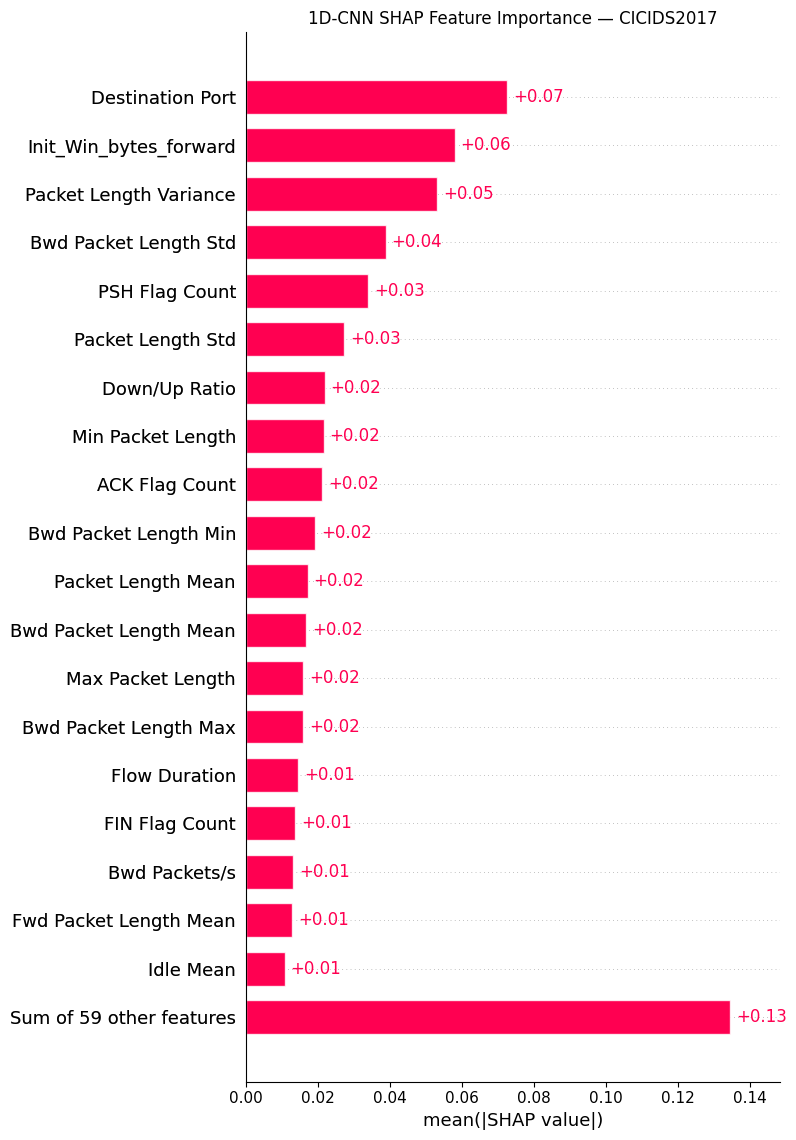

In [155]:
import matplotlib.pyplot as plt

shap.plots.bar(
    shap_values_cnn_attack,
    max_display=20,
    show=False
)

plt.title(
    "1D-CNN SHAP Feature Importance — CICIDS2017"
)

plt.tight_layout()
plt.show()

In [156]:
import os

os.makedirs(SHAP_DIR, exist_ok=True)

np.save(
    os.path.join(
        SHAP_DIR,
        "cnn_attack_shap_values.npy"
    ),
    shap_values_cnn_attack.values
)

cnn_importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_Absolute_SHAP": np.abs(
        shap_values_cnn_attack.values
    ).mean(axis=0)
})

cnn_importance_df = cnn_importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

cnn_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "cnn_global_shap_importance.csv"
    ),
    index=False
)

print("CNN SHAP results saved successfully!")

display(cnn_importance_df.head(20))

CNN SHAP results saved successfully!


,Feature,Mean_Absolute_SHAP
0,Destination Port,0.072622
66,Init_Win_bytes_forward,0.058046
42,Packet Length Variance,0.053205
13,Bwd Packet Length Std,0.038916
46,PSH Flag Count,0.034111
41,Packet Length Std,0.027447
51,Down/Up Ratio,0.021949
38,Min Packet Length,0.021618
47,ACK Flag Count,0.021317
11,Bwd Packet Length Min,0.019324


In [157]:
import numpy as np
import pandas as pd

cnn_attack_importance = {}

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    attack_shap = shap_values_cnn_attack.values[mask]

    mean_importance = np.abs(
        attack_shap
    ).mean(axis=0)

    cnn_attack_importance[attack] = mean_importance

cnn_attack_importance_df = pd.DataFrame(
    cnn_attack_importance,
    index=feature_cols
)

print("CNN attack-specific SHAP importance:")

display(cnn_attack_importance_df.head(20))

CNN attack-specific SHAP importance:


,BENIGN,Bot,DDoS,PortScan
Destination Port,0.039386,0.084316,0.056948,0.109840
Flow Duration,0.008672,0.018034,0.014039,0.017849
Total Fwd Packets,0.001056,0.000153,0.000533,0.000464
Total Backward Packets,0.000431,0.000135,0.000630,0.000217
Total Length of Fwd Packets,0.003593,0.001443,0.002918,0.001109
Total Length of Bwd Packets,0.000097,0.000064,0.000111,0.000043
Fwd Packet Length Max,0.012087,0.004527,0.009725,0.004337
Fwd Packet Length Min,0.003335,0.002178,0.010558,0.004799
Fwd Packet Length Mean,0.007087,0.006215,0.027025,0.011513
Fwd Packet Length Std,0.014879,0.004393,0.006830,0.006273


In [159]:
import numpy as np
import pandas as pd

cnn_attack_importance = {}

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    attack_shap = shap_values_cnn_attack.values[mask]

    mean_importance = np.abs(
        attack_shap
    ).mean(axis=0)

    cnn_attack_importance[attack] = mean_importance

cnn_attack_importance_df = pd.DataFrame(
    cnn_attack_importance,
    index=feature_cols
)

print("CNN attack-specific SHAP importance:")

display(cnn_attack_importance_df.head(20))

CNN attack-specific SHAP importance:


,BENIGN,Bot,DDoS,PortScan
Destination Port,0.039386,0.084316,0.056948,0.109840
Flow Duration,0.008672,0.018034,0.014039,0.017849
Total Fwd Packets,0.001056,0.000153,0.000533,0.000464
Total Backward Packets,0.000431,0.000135,0.000630,0.000217
Total Length of Fwd Packets,0.003593,0.001443,0.002918,0.001109
Total Length of Bwd Packets,0.000097,0.000064,0.000111,0.000043
Fwd Packet Length Max,0.012087,0.004527,0.009725,0.004337
Fwd Packet Length Min,0.003335,0.002178,0.010558,0.004799
Fwd Packet Length Mean,0.007087,0.006215,0.027025,0.011513
Fwd Packet Length Std,0.014879,0.004393,0.006830,0.006273


In [160]:
for attack in ["Bot", "DDoS", "PortScan"]:

    print("\n" + "=" * 50)
    print("Attack:", attack)
    print("=" * 50)

    top_features = (
        cnn_attack_importance_df[attack]
        .sort_values(ascending=False)
        .head(10)
    )

    result = top_features.reset_index()

    result.columns = [
        "Feature",
        "Mean Absolute SHAP"
    ]

    display(result)


Attack: Bot


,Feature,Mean Absolute SHAP
0,Destination Port,0.084316
1,Init_Win_bytes_forward,0.071017
2,PSH Flag Count,0.040353
3,Flow Duration,0.018034
4,Bwd Packet Length Std,0.014452
5,FIN Flag Count,0.011292
6,Bwd Packet Length Min,0.010810
7,Bwd Packet Length Mean,0.010237
8,URG Flag Count,0.010112
9,Packet Length Variance,0.009994



Attack: DDoS


,Feature,Mean Absolute SHAP
0,Packet Length Variance,0.178667
1,Bwd Packet Length Std,0.106567
2,Init_Win_bytes_forward,0.097658
3,Packet Length Std,0.083945
4,Min Packet Length,0.062985
5,Destination Port,0.056948
6,Packet Length Mean,0.054139
7,Max Packet Length,0.046519
8,Bwd Packet Length Max,0.046432
9,Down/Up Ratio,0.043235



Attack: PortScan


,Feature,Mean Absolute SHAP
0,Destination Port,0.109840
1,PSH Flag Count,0.063363
2,Bwd Packets/s,0.037566
3,Init_Win_bytes_forward,0.027049
4,Bwd Packet Length Min,0.019705
5,Flow Duration,0.017849
6,Bwd Packet Length Std,0.015465
7,Down/Up Ratio,0.013479
8,FIN Flag Count,0.013193
9,Idle Mean,0.012728


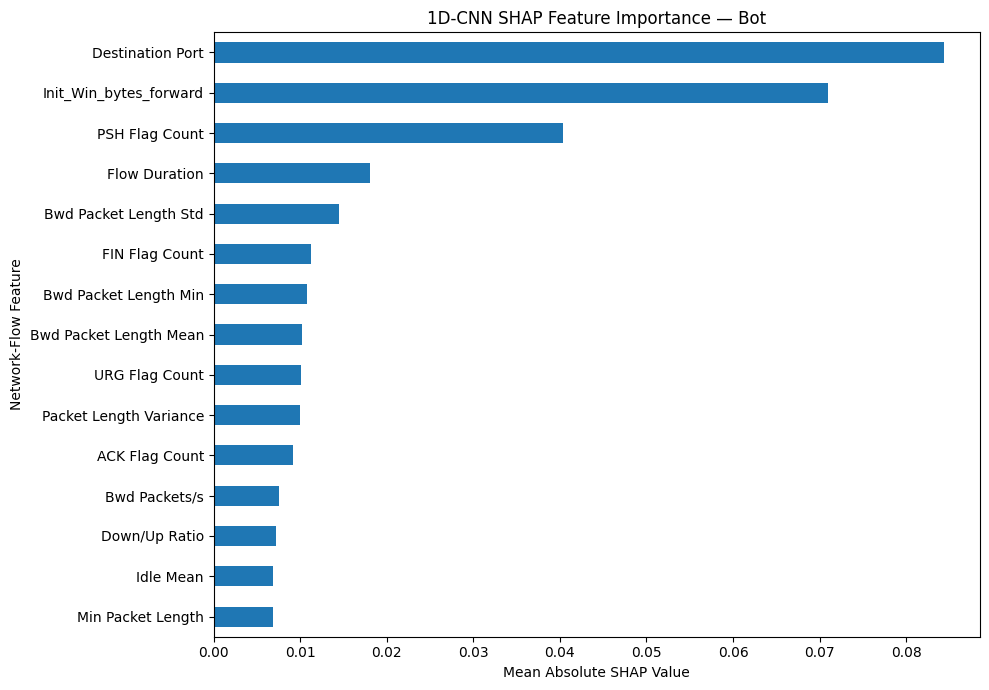

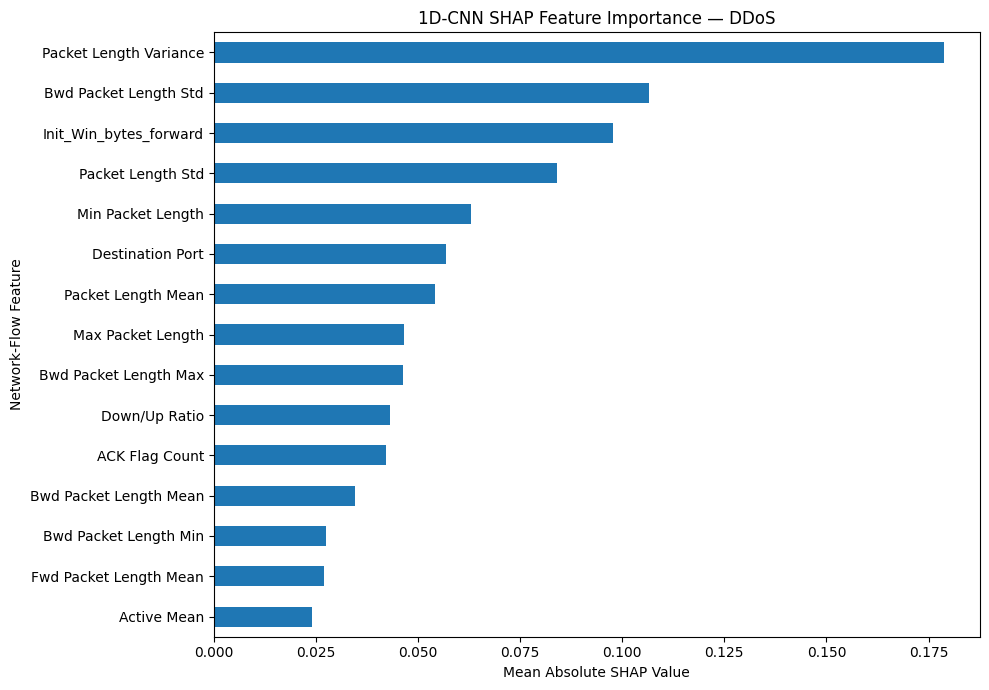

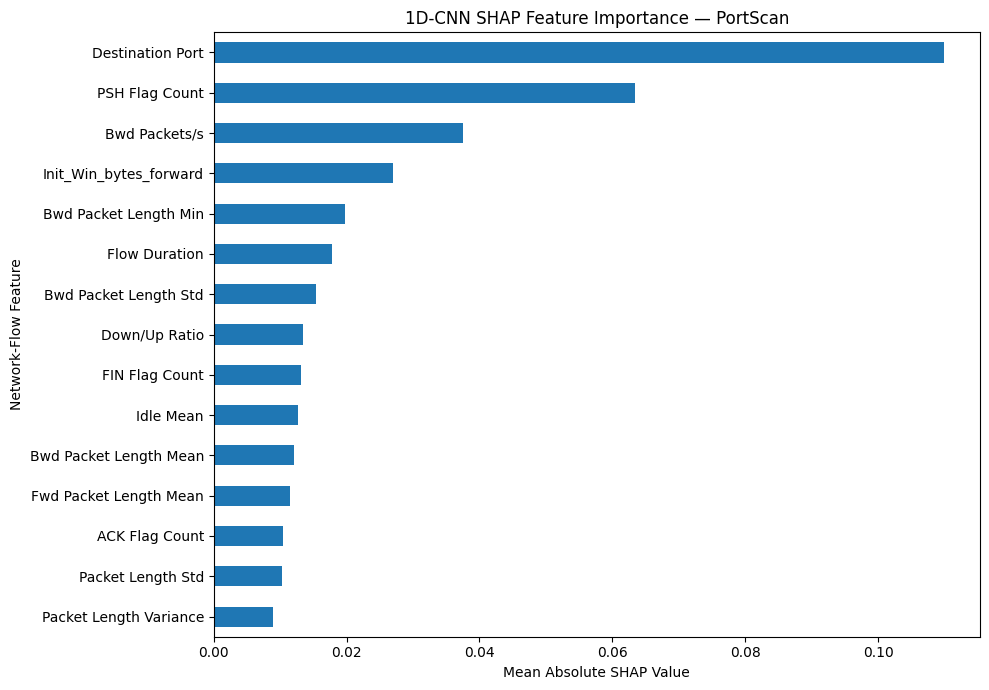

In [161]:
import matplotlib.pyplot as plt
import os

os.makedirs(SHAP_DIR, exist_ok=True)

for attack in ["Bot", "DDoS", "PortScan"]:

    top_features = (
        cnn_attack_importance_df[attack]
        .sort_values(ascending=False)
        .head(15)
        .sort_values()
    )

    plt.figure(figsize=(10, 7))

    top_features.plot(
        kind="barh"
    )

    plt.title(
        f"1D-CNN SHAP Feature Importance — {attack}"
    )

    plt.xlabel("Mean Absolute SHAP Value")
    plt.ylabel("Network-Flow Feature")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            SHAP_DIR,
            f"cnn_shap_{attack.lower()}_importance.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [162]:
from scipy.stats import spearmanr

attack_comparison_results = []

for attack in ["Bot", "DDoS", "PortScan"]:

    cnn_values = cnn_attack_importance_df[attack]
    lstm_values = lstm_attack_importance_df[attack]

    correlation, p_value = spearmanr(
        cnn_values,
        lstm_values
    )

    attack_comparison_results.append({
        "Attack": attack,
        "Spearman_Correlation": correlation,
        "P_Value": p_value
    })

cnn_lstm_attack_comparison_df = pd.DataFrame(
    attack_comparison_results
)

display(cnn_lstm_attack_comparison_df)

,Attack,Spearman_Correlation,P_Value
0,Bot,0.885396,5.325337e-27
1,DDoS,0.926745,4.779950e-34
2,PortScan,0.925958,7.069099e-34


In [163]:
os.makedirs(SHAP_DIR, exist_ok=True)

cnn_attack_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "cnn_attack_specific_shap.csv"
    )
)

cnn_lstm_attack_comparison_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "cnn_lstm_attack_shap_comparison.csv"
    ),
    index=False
)

print("CNN attack-specific SHAP results saved successfully!")

CNN attack-specific SHAP results saved successfully!


In [164]:
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity

cnn_shap = np.asarray(
    shap_values_cnn_attack.values
)

cnn_consistency_results = []

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    attack_shap = cnn_shap[mask]

    similarity_matrix = cosine_similarity(
        attack_shap
    )

    upper_indices = np.triu_indices(
        len(attack_shap),
        k=1
    )

    mean_similarity = (
        similarity_matrix[upper_indices].mean()
    )

    cnn_consistency_results.append({
        "Attack": attack,
        "Samples": len(attack_shap),
        "Mean_Cosine_Similarity": mean_similarity
    })

cnn_consistency_df = pd.DataFrame(
    cnn_consistency_results
)

display(cnn_consistency_df)

,Attack,Samples,Mean_Cosine_Similarity
0,BENIGN,20,0.082393
1,Bot,20,0.502034
2,DDoS,20,0.168492
3,PortScan,20,0.635680


In [165]:
from sklearn.metrics.pairwise import (
    cosine_similarity,
    euclidean_distances
)

cnn_local_results = []

for attack in ["BENIGN", "Bot", "DDoS", "PortScan"]:

    mask = attack_labels_sample == attack

    X_group = X_cnn_attack_sample[mask]
    SHAP_group = cnn_shap[mask]

    distances = euclidean_distances(X_group)

    np.fill_diagonal(distances, np.inf)

    nearest_indices = np.argmin(
        distances,
        axis=1
    )

    feature_distances = distances[
        np.arange(len(X_group)),
        nearest_indices
    ]

    explanation_similarities = []

    for i, j in enumerate(nearest_indices):

        similarity = cosine_similarity(
            SHAP_group[i].reshape(1, -1),
            SHAP_group[j].reshape(1, -1)
        )[0, 0]

        explanation_similarities.append(similarity)

    cnn_local_results.append({
        "Attack": attack,
        "Samples": len(X_group),
        "Mean_Nearest_Feature_Distance":
            np.mean(feature_distances),
        "Mean_Local_SHAP_Similarity":
            np.mean(explanation_similarities)
    })

cnn_local_consistency_df = pd.DataFrame(
    cnn_local_results
)

display(cnn_local_consistency_df)

,Attack,Samples,Mean_Nearest_Feature_Distance,Mean_Local_SHAP_Similarity
0,BENIGN,20,3.325908,0.449400
1,Bot,20,0.383085,0.579542
2,DDoS,20,2.169326,0.605056
3,PortScan,20,0.402104,0.682347


In [166]:
cnn_lstm_consistency_df = (
    cnn_consistency_df[
        ["Attack", "Mean_Cosine_Similarity"]
    ]
    .rename(columns={
        "Mean_Cosine_Similarity": "CNN_Global"
    })
    .merge(
        cnn_local_consistency_df[
            ["Attack", "Mean_Local_SHAP_Similarity"]
        ].rename(columns={
            "Mean_Local_SHAP_Similarity": "CNN_Local"
        }),
        on="Attack"
    )
    .merge(
        consistency_df[
            ["Attack", "Mean_Cosine_Similarity"]
        ].rename(columns={
            "Mean_Cosine_Similarity": "LSTM_Global"
        }),
        on="Attack"
    )
    .merge(
        local_consistency_df[
            ["Attack", "Mean_Local_SHAP_Similarity"]
        ].rename(columns={
            "Mean_Local_SHAP_Similarity": "LSTM_Local"
        }),
        on="Attack"
    )
)

display(cnn_lstm_consistency_df)

,Attack,CNN_Global,CNN_Local,LSTM_Global,LSTM_Local
0,BENIGN,0.082393,0.449400,0.076340,0.265910
1,Bot,0.502034,0.579542,0.290465,0.317432
2,DDoS,0.168492,0.605056,0.049905,0.337865
3,PortScan,0.635680,0.682347,0.318018,0.383967


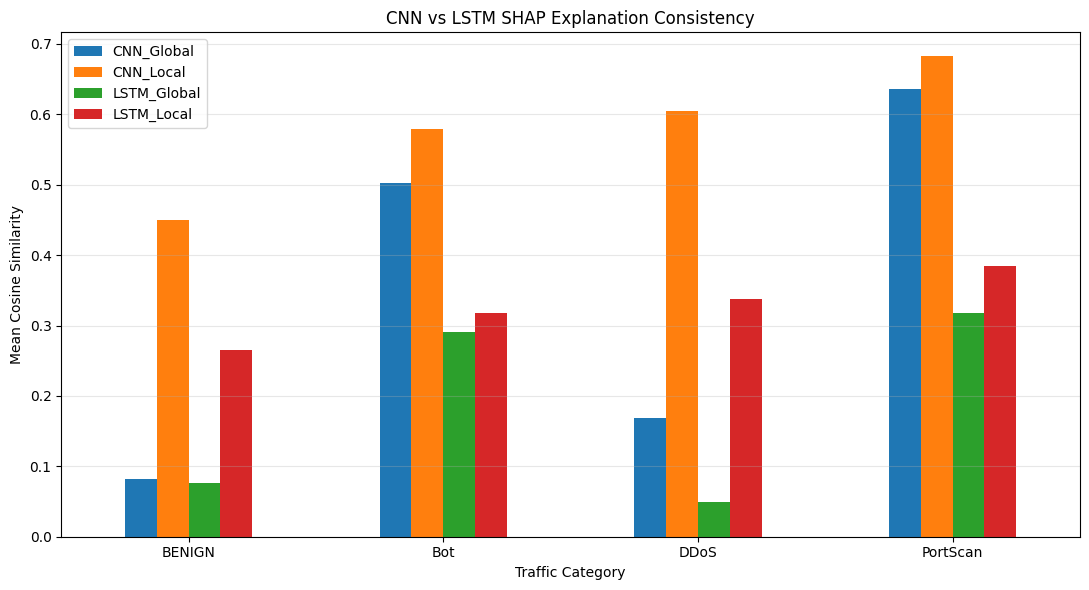

In [168]:
import matplotlib.pyplot as plt

plot_df = cnn_lstm_consistency_df.set_index("Attack")

plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "CNN vs LSTM SHAP Explanation Consistency"
)

plt.ylabel("Mean Cosine Similarity")
plt.xlabel("Traffic Category")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [169]:
import os

os.makedirs(EVAL_DIR, exist_ok=True)

cnn_consistency_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "cnn_shap_global_consistency.csv"
    ),
    index=False
)

cnn_local_consistency_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "cnn_shap_local_consistency.csv"
    ),
    index=False
)

cnn_lstm_consistency_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "cnn_lstm_consistency_comparison.csv"
    ),
    index=False
)

print("CNN consistency results saved successfully!")

CNN consistency results saved successfully!


In [170]:
import numpy as np
import pandas as pd
import time

X_fidelity_cnn = np.asarray(
    X_cnn_attack_sample,
    dtype=np.float32
)

cnn_shap_fidelity = np.asarray(
    shap_values_cnn_attack.values
)

assert X_fidelity_cnn.shape == cnn_shap_fidelity.shape

print("CNN input shape:", X_fidelity_cnn.shape)
print("CNN SHAP shape:", cnn_shap_fidelity.shape)

CNN input shape: (80, 78)
CNN SHAP shape: (80, 78)


In [171]:
import numpy as np
import pandas as pd
import time

X_fidelity_cnn = np.asarray(
    X_cnn_attack_sample,
    dtype=np.float32
)

cnn_shap_fidelity = np.asarray(
    shap_values_cnn_attack.values
)

assert X_fidelity_cnn.shape == cnn_shap_fidelity.shape

print("CNN input shape:", X_fidelity_cnn.shape)
print("CNN SHAP shape:", cnn_shap_fidelity.shape)

CNN input shape: (80, 78)
CNN SHAP shape: (80, 78)


In [173]:
def cnn_predict_fidelity(X):

    X = np.asarray(X, dtype=np.float32)

    X = X.reshape(-1, 78, 1)

    probabilities = cnn_model.predict(
        X,
        batch_size=1024,
        verbose=0
    )

    return probabilities.ravel()

In [174]:
rng = np.random.default_rng(42)

feature_counts = [1, 5, 10, 20]

# Reference values from the training set only
background_values = np.median(
    X_train_scaled,
    axis=0
).astype(np.float32)

original_prob = cnn_predict_fidelity(
    X_fidelity_cnn
)

cnn_fidelity_results = []

for k in feature_counts:

    for method in ["top", "random"]:

        X_modified = X_fidelity_cnn.copy()

        for i in range(len(X_modified)):

            if method == "top":

                selected_features = np.argsort(
                    np.abs(cnn_shap_fidelity[i])
                )[-k:]

            else:

                selected_features = rng.choice(
                    X_modified.shape[1],
                    size=k,
                    replace=False
                )

            X_modified[i, selected_features] = (
                background_values[selected_features]
            )

        modified_prob = cnn_predict_fidelity(
            X_modified
        )

        probability_change = np.abs(
            original_prob - modified_prob
        )

        cnn_fidelity_results.append({
            "Features_Removed": k,
            "Method": method,
            "Mean_Absolute_Probability_Change":
                probability_change.mean()
        })

cnn_fidelity_df = pd.DataFrame(
    cnn_fidelity_results
)

display(cnn_fidelity_df)

,Features_Removed,Method,Mean_Absolute_Probability_Change
0,1,top,0.129115
1,1,random,0.010182
2,5,top,0.182024
3,5,random,0.036818
4,10,top,0.193658
5,10,random,0.049999
6,20,top,0.197237
7,20,random,0.063596


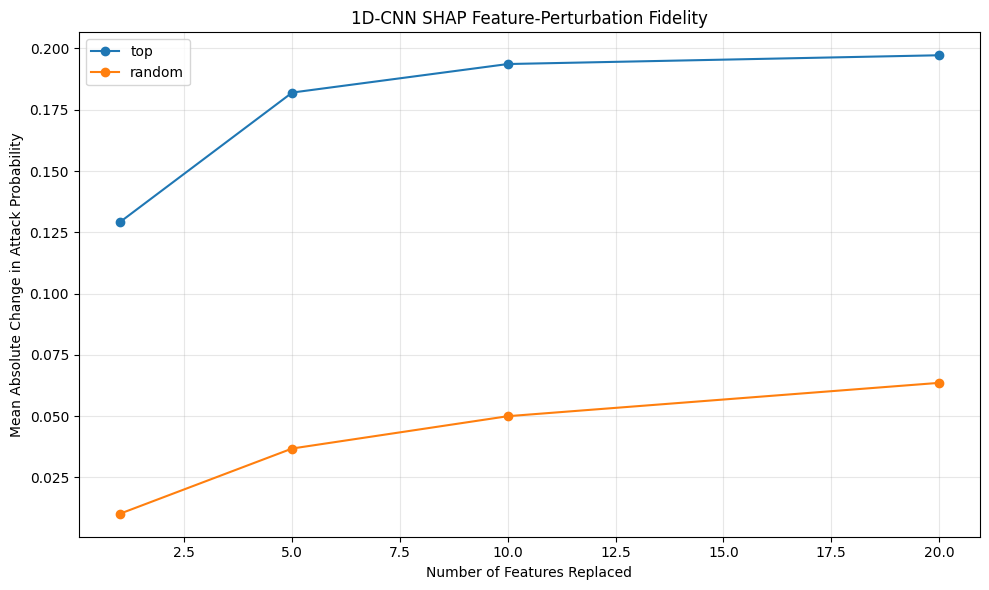

In [175]:
import matplotlib.pyplot as plt

plot_df = cnn_fidelity_df.pivot(
    index="Features_Removed",
    columns="Method",
    values="Mean_Absolute_Probability_Change"
)

plt.figure(figsize=(10, 6))

for method in ["top", "random"]:

    plt.plot(
        plot_df.index,
        plot_df[method],
        marker="o",
        label=method
    )

plt.title(
    "1D-CNN SHAP Feature-Perturbation Fidelity"
)

plt.xlabel("Number of Features Replaced")
plt.ylabel("Mean Absolute Change in Attack Probability")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [176]:
import os

os.makedirs(EVAL_DIR, exist_ok=True)

cnn_fidelity_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "cnn_shap_perturbation_fidelity.csv"
    ),
    index=False
)

print("CNN SHAP fidelity results saved successfully!")

CNN SHAP fidelity results saved successfully!


In [177]:
import numpy as np
import pandas as pd
import time
import os

X_latency_cnn = np.asarray(
    X_cnn_attack_sample,
    dtype=np.float32
)

batch_sizes = [1, 5, 10, 20, 40, 80]

print("CNN latency sample shape:", X_latency_cnn.shape)
print("Batch sizes:", batch_sizes)

CNN latency sample shape: (80, 78)
Batch sizes: [1, 5, 10, 20, 40, 80]


In [178]:
# Warm-up explanation
_ = explainer_cnn(
    X_latency_cnn[:1],
    max_evals=2 * 78 + 1
)

print("CNN SHAP warm-up completed!")

CNN SHAP warm-up completed!


In [179]:
cnn_latency_results = []

repetitions = 3

for batch_size in batch_sizes:

    total_times = []

    print("\nTesting batch size:", batch_size)

    X_batch = X_latency_cnn[:batch_size]

    for repeat in range(repetitions):

        start_time = time.perf_counter()

        _ = explainer_cnn(
            X_batch,
            max_evals=2 * 78 + 1
        )

        elapsed_time = (
            time.perf_counter() - start_time
        )

        total_times.append(elapsed_time)

    mean_total = np.mean(total_times)
    std_total = np.std(total_times, ddof=1)

    mean_per_record = mean_total / batch_size

    cnn_latency_results.append({
        "Batch_Size": batch_size,
        "Mean_Total_Seconds": mean_total,
        "Std_Total_Seconds": std_total,
        "Mean_Seconds_Per_Record": mean_per_record
    })

cnn_latency_summary_df = pd.DataFrame(
    cnn_latency_results
)

display(cnn_latency_summary_df)


Testing batch size: 1

Testing batch size: 5

Testing batch size: 10

Testing batch size: 20


PermutationExplainer explainer: 21it [00:12,  3.01s/it]



Testing batch size: 40


PermutationExplainer explainer: 41it [00:17,  1.08s/it]
PermutationExplainer explainer: 41it [00:17,  1.03it/s]
PermutationExplainer explainer: 41it [00:19,  1.13s/it]



Testing batch size: 80


PermutationExplainer explainer: 81it [00:48,  1.37it/s]
PermutationExplainer explainer: 81it [00:39,  1.46it/s]
PermutationExplainer explainer: 81it [00:33,  1.68it/s]


,Batch_Size,Mean_Total_Seconds,Std_Total_Seconds,Mean_Seconds_Per_Record
0,1,0.349773,0.002208,0.349773
1,5,3.122724,0.657289,0.624545
2,10,4.135975,0.341699,0.413597
3,20,9.593475,2.187921,0.479674
4,40,17.960551,1.087407,0.449014
5,80,40.618133,7.629225,0.507727


<Figure size 1000x600 with 0 Axes>

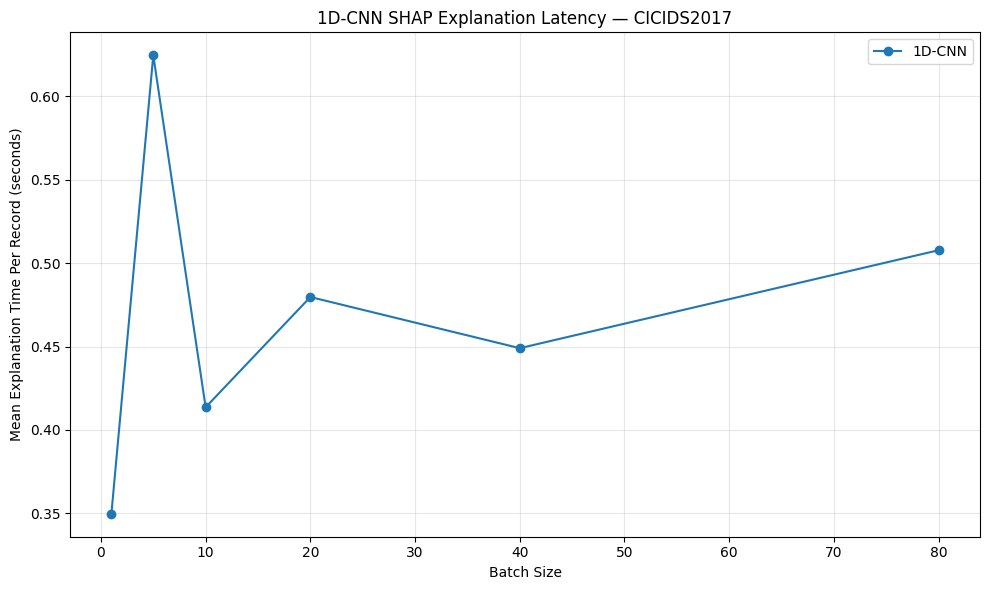

In [181]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    cnn_latency_summary_df["Batch_Size"],
    cnn_latency_summary_df["Mean_Seconds_Per_Record"],
    marker="o",
    label="1D-CNN"
)

plt.title(
    "1D-CNN SHAP Explanation Latency — CICIDS2017"
)

plt.xlabel("Batch Size")
plt.ylabel("Mean Explanation Time Per Record (seconds)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [182]:
lstm_latency_reference = pd.DataFrame({
    "Batch_Size": [1, 5, 10, 20, 40, 80],
    "LSTM_Seconds_Per_Record": [
        0.627569,
        0.574337,
        0.503243,
        0.475492,
        0.510952,
        0.441108
    ]
})

cnn_lstm_latency_df = (
    cnn_latency_summary_df[
        ["Batch_Size", "Mean_Seconds_Per_Record"]
    ]
    .rename(columns={
        "Mean_Seconds_Per_Record":
            "CNN_Seconds_Per_Record"
    })
    .merge(
        lstm_latency_reference,
        on="Batch_Size"
    )
)

cnn_lstm_latency_df["CNN_vs_LSTM_Speedup"] = (
    cnn_lstm_latency_df["LSTM_Seconds_Per_Record"]
    / cnn_lstm_latency_df["CNN_Seconds_Per_Record"]
)

display(cnn_lstm_latency_df)

,Batch_Size,CNN_Seconds_Per_Record,LSTM_Seconds_Per_Record,CNN_vs_LSTM_Speedup
0,1,0.349773,0.627569,1.794216
1,5,0.624545,0.574337,0.919609
2,10,0.413597,0.503243,1.216746
3,20,0.479674,0.475492,0.991282
4,40,0.449014,0.510952,1.137943
5,80,0.507727,0.441108,0.868790


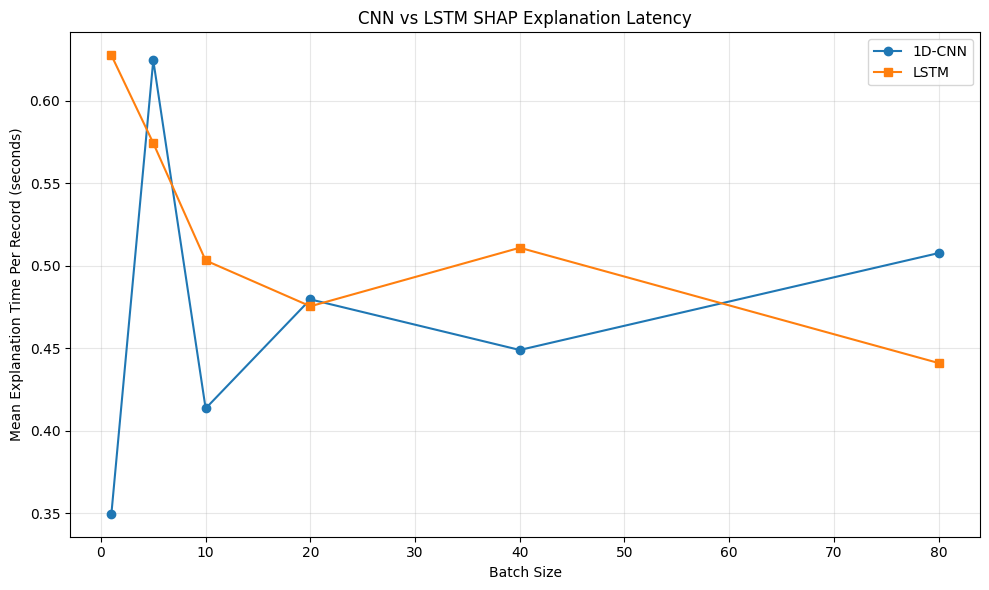

In [183]:
plt.figure(figsize=(10, 6))

plt.plot(
    cnn_lstm_latency_df["Batch_Size"],
    cnn_lstm_latency_df["CNN_Seconds_Per_Record"],
    marker="o",
    label="1D-CNN"
)

plt.plot(
    cnn_lstm_latency_df["Batch_Size"],
    cnn_lstm_latency_df["LSTM_Seconds_Per_Record"],
    marker="s",
    label="LSTM"
)

plt.title("CNN vs LSTM SHAP Explanation Latency")

plt.xlabel("Batch Size")
plt.ylabel("Mean Explanation Time Per Record (seconds)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [184]:
import os

os.makedirs(EVAL_DIR, exist_ok=True)

cnn_latency_summary_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "cnn_shap_latency.csv"
    ),
    index=False
)

cnn_lstm_latency_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "cnn_lstm_shap_latency_comparison.csv"
    ),
    index=False
)

print("CNN SHAP latency results saved successfully!")

CNN SHAP latency results saved successfully!


In [185]:
import pandas as pd
import os

final_detection_df = pd.DataFrame({
    "Model": ["XGBoost", "1D-CNN", "LSTM"],
    "Macro F1": [0.677502, 0.698048, 0.824474],
    "Weighted F1": [0.719943, 0.735142, 0.834752],
    "Precision": [0.998668, 0.912766, 0.748358],
    "Recall": [0.347349, 0.400159, 0.825908],
    "ROC-AUC": [0.788191, 0.755375, 0.859919],
    "PR-AUC": [0.807211, 0.748061, 0.856631]
})

display(final_detection_df)

os.makedirs(RESULT_DIR, exist_ok=True)

final_detection_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "final_three_model_detection_comparison.csv"
    ),
    index=False
)

print("Final detection comparison saved successfully!")

,Model,Macro F1,Weighted F1,Precision,Recall,ROC-AUC,PR-AUC
0,XGBoost,0.677502,0.719943,0.998668,0.347349,0.788191,0.807211
1,1D-CNN,0.698048,0.735142,0.912766,0.400159,0.755375,0.748061
2,LSTM,0.824474,0.834752,0.748358,0.825908,0.859919,0.856631


Final detection comparison saved successfully!
